# Exploratory data analysis and preparation


## Import libraries


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from scipy.stats import chi2_contingency
from sklearn.model_selection import StratifiedGroupKFold


# 3. Review the cleaned data


## 3.1. Load and check the cleaned data


In [2]:
# 3.1. Load and check the cleaned data
DATA_PATH = Path('data')
if not DATA_PATH.is_dir():
    raise FileNotFoundError('Run the notebook from the project root, with data/ beside notebooks/.')
data = pd.read_pickle(DATA_PATH / 'data_processed.pkl')

data.head()
required_sentiments = {'Negative', 'Neutral', 'Positive'}
observed_sentiments = set(data['sentiment'].dropna().astype(str).unique())
if observed_sentiments != required_sentiments:
    raise ValueError(f'Unexpected sentiment labels: {observed_sentiments}')


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1157800 entries, 0 to 1157799
Data columns (total 12 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   review_id          1157800 non-null  string        
 1   item_id            1157800 non-null  string        
 2   title              1157800 non-null  string        
 3   text               1157800 non-null  string        
 4   date               1157800 non-null  datetime64[ns]
 5   review_rating      1157800 non-null  Int64         
 6   language           1157800 non-null  category      
 7   sentiment          1157800 non-null  category      
 8   name               1157800 non-null  string        
 9   price_interval     1157800 non-null  category      
 10  restaurant_rating  1157795 non-null  Float64       
 11  type               1157800 non-null  object        
dtypes: Float64(1), Int64(1), category(3), datetime64[ns](1), object(1), string(5)
memory

In [4]:
# 3.1. Load and check the cleaned data
quality_summary = pd.Series({
    'rows': len(data),
    'columns': data.shape[1],
    'missing_values': data.isna().sum().sum(),
    'missing_restaurant_ratings': data['restaurant_rating'].isna().sum(),
    'duplicated_review_id': data['review_id'].duplicated().sum(),
    'restaurants': data['item_id'].nunique(),
    'minimum_date': data['date'].min(),
    'maximum_date': data['date'].max()
}, name='result').to_frame()

quality_summary

,result
rows,1157800
columns,12
missing_values,5
missing_restaurant_ratings,5
duplicated_review_id,0
restaurants,10056
minimum_date,2002-11-11 00:00:00
maximum_date,2023-06-10 00:00:00


The cleaned dataset has 1,157,800 reviews from 10,056 restaurants. Reviews are labeled Spanish or English and cover November 2002 to June 2023. Review IDs are unique. Five restaurant ratings remain missing because their original value was invalid (`-10`). The other exported columns have no missing values.


## 3.2. Units of analysis and target variable


The project uses three units of analysis:

- **Review:** training the sentiment classifier.
- **Restaurant:** reputation diagnosis and alerts.
- **Competitive group:** comparison by cuisine type and price range.

`sentiment` is a proxy label based on `review_rating`: 1–2 = Negative, 3 = Neutral, and 4–5 = Positive. The classifier does not use either rating as an input, because that would leak information about the target.


In [5]:
# The project uses three units of analysis:
print(f'Reviews: {data["review_id"].nunique():,}')
print(f'Restaurants: {data["item_id"].nunique():,}')
print(f'Languages: {data["language"].nunique()}')

Reviews: 1,157,800
Restaurants: 10,056
Languages: 2


# 4. Project-focused exploratory analysis

## 4.1. Target class distribution


In [6]:
# 4. Project-focused exploratory analysis
sentiment_summary = (
    data['sentiment']
    .value_counts(sort=False)
    .rename_axis('sentiment')
    .to_frame('reviews')
)

sentiment_summary['percentage'] = (
    sentiment_summary['reviews']
    .div(sentiment_summary['reviews'].sum())
    .mul(100)
    .round(2)
)

sentiment_summary

,reviews,percentage
sentiment,,
Negative,160177,13.83
Neutral,132627,11.46
Positive,864996,74.71


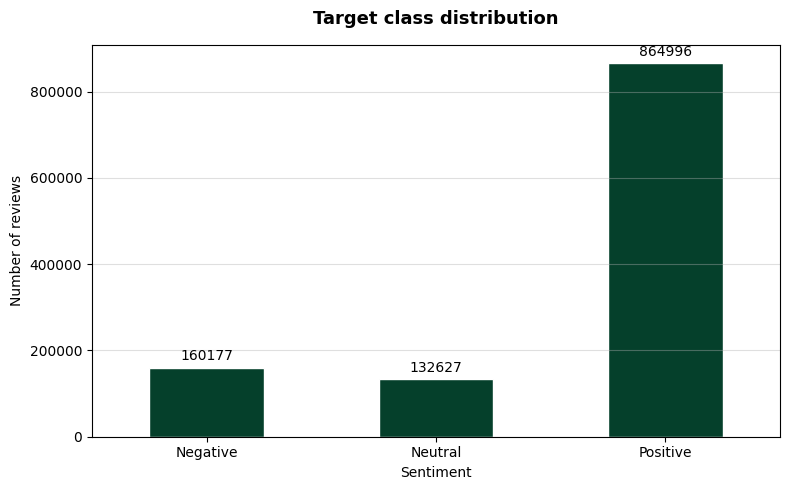

In [7]:
# 4. Project-focused exploratory analysis
ax = sentiment_summary['reviews'].plot(
    kind='bar',
    figsize=(8, 5),
    color='#05402B',
    edgecolor='white'
)

ax.set_title(
    'Target class distribution',
    fontsize=13,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('Sentiment')
ax.set_ylabel('Number of reviews')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.4)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

Positive reviews make up 74.71%, Negative reviews 13.83%, and Neutral reviews 11.46%. A classifier that always predicts Positive would reach 74.71% accuracy.

Model comparison will focus on macro F1, Negative recall, balanced accuracy, and the confusion matrix. Class weights will address the imbalance without dropping or oversampling reviews.


## 4.2. Review text characteristics


In [8]:
data['title_char_count'] = data['title'].str.len()
data['text_char_count'] = data['text'].str.len()
data['text_word_count'] = data['text'].str.count(r'\S+')

In [9]:
# 4.2. Review text characteristics
text_length_summary = (
    data[
        [
            'title_char_count',
            'text_char_count',
            'text_word_count'
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
    .T
    .round(2)
)

text_length_summary

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
title_char_count,1157800.0,23.25,13.84,0.0,5.0,8.0,13.0,20.0,30.0,49.0,70.0,128.0
text_char_count,1157800.0,353.69,310.06,3.0,101.0,111.0,165.0,260.0,430.0,902.0,1557.0,15874.0
text_word_count,1157800.0,61.94,55.51,1.0,15.0,18.0,28.0,45.0,76.0,161.0,278.0,2538.0


In [10]:
# 4.2. Review text characteristics
text_quality_summary = pd.Series({
    'empty_text': data['text'].str.strip().eq('').sum(),
    'up_to_3_words': data['text_word_count'].le(3).sum(),
    'up_to_5_words': data['text_word_count'].le(5).sum()
}, name='reviews').to_frame()

display(text_quality_summary)

short_reviews = data.loc[
    data['text_word_count'].le(3),
    [
        'review_id',
        'language',
        'sentiment',
        'review_rating',
        'title',
        'text',
        'text_word_count'
    ]
]

display(short_reviews.head(20))

,reviews
empty_text,0
up_to_3_words,277
up_to_5_words,502


,review_id,language,sentiment,review_rating,title,text,text_word_count
5285,15453884,es,Positive,4,Estupendo,Estupendo,1
5287,15453844,es,Positive,5,muy buen arabe,muy buen arabe,3
10480,15455640,en,Positive,5,La mejor hamburguesa,La mejor hamburguesa,3
10481,15455592,es,Neutral,3,"ricas hamburguesas, ricas.","ricas hamburguesas, ricas.",3
10483,15455591,es,Positive,4,Auténtico 100%,Auténtico 100%,2
11276,22636602,es,Positive,4,Ricas Hamburguesas,Ricas Hamburguesas,2
11280,19416385,es,Positive,5,MEJOR HAMBURGUESA MADRID,MEJOR HAMBURGUESA MADRID,3
11282,19260423,es,Positive,4,Muy buenas hamburguesas!!,Muy buenas hamburguesas!!,3
11285,17045964,en,Neutral,3,super burguers,super burguers,2
13868,15456646,es,Negative,1,Malo,Malo,1


In [11]:
# 4.2. Review text characteristics
text_length_by_sentiment = (
    data
    .groupby('sentiment', observed=True)
    .agg(
        reviews=('review_id', 'size'),
        mean_words=('text_word_count', 'mean'),
        median_words=('text_word_count', 'median'),
        p95_words=(
            'text_word_count',
            lambda values: values.quantile(0.95)
        )
    )
    .round(2)
)

text_length_by_language = (
    data
    .groupby('language', observed=True)
    .agg(
        reviews=('review_id', 'size'),
        mean_words=('text_word_count', 'mean'),
        median_words=('text_word_count', 'median'),
        p95_words=(
            'text_word_count',
            lambda values: values.quantile(0.95)
        )
    )
    .round(2)
)

display(text_length_by_sentiment)
display(text_length_by_language)

,reviews,mean_words,median_words,p95_words
sentiment,,,,
Negative,160177,90.75,69.0,233
Neutral,132627,72.97,55.0,185
Positive,864996,54.92,41.0,137


,reviews,mean_words,median_words,p95_words
language,,,,
en,199116,66.55,50.0,170
es,958684,60.99,44.0,158


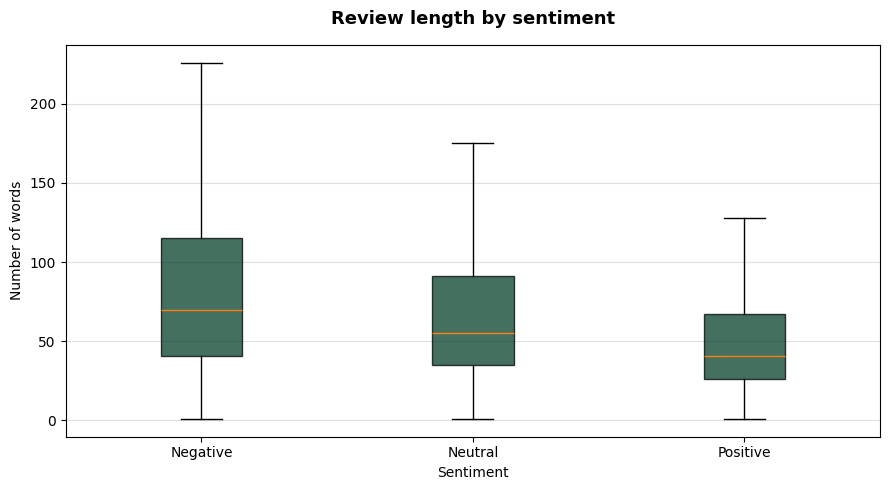

In [12]:
# 4.2. Review text characteristics
plot_sample = data.sample(
    n=min(100_000, len(data)),
    random_state=42
)

sentiment_order = [
    'Negative',
    'Neutral',
    'Positive'
]

word_count_groups = [
    plot_sample.loc[
        plot_sample['sentiment'] == sentiment,
        'text_word_count'
    ]
    for sentiment in sentiment_order
]

fig, ax = plt.subplots(figsize=(9, 5))

boxplot = ax.boxplot(
    word_count_groups,
    tick_labels=sentiment_order,
    showfliers=False,
    patch_artist=True
)

for box in boxplot['boxes']:
    box.set_facecolor('#05402B')
    box.set_alpha(0.75)

ax.set_title(
    'Review length by sentiment',
    fontsize=13,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('Sentiment')
ax.set_ylabel('Number of words')
ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

The median review has 45 words and the mean is 61.94. About 95% have at most 161 words and 99% have at most 278; the longest review has 2,538 words and is kept.

There are no empty review texts. Reviews with five words or fewer are kept because they can still express an opinion.

Median length is 69 words for Negative, 55 for Neutral, and 41 for Positive reviews. It is 50 for reviews labeled English and 44 for those labeled Spanish. Model results will be checked by class and source language label.

No text is removed or shortened based on length.


## 4.3. Reviews by source language label


In [13]:
# 4.3. Reviews by source language label
language_summary = (
    data['language']
    .value_counts()
    .rename_axis('language')
    .to_frame('reviews')
)

language_summary['percentage'] = (
    language_summary['reviews']
    .div(language_summary['reviews'].sum())
    .mul(100)
    .round(2)
)

language_summary

,reviews,percentage
language,,
es,958684,82.8
en,199116,17.2


In [14]:
# 4.3. Reviews by source language label
language_sentiment_counts = pd.crosstab(
    data['language'],
    data['sentiment']
)

language_sentiment_percentage = (
    pd.crosstab(
        data['language'],
        data['sentiment'],
        normalize='index'
    )
    .mul(100)
    .round(2)
)

display(language_sentiment_counts)
display(language_sentiment_percentage)

sentiment,Negative,Neutral,Positive
language,,,
en,18970,16773,163373
es,141207,115854,701623


sentiment,Negative,Neutral,Positive
language,,,
en,9.53,8.42,82.05
es,14.73,12.08,73.19


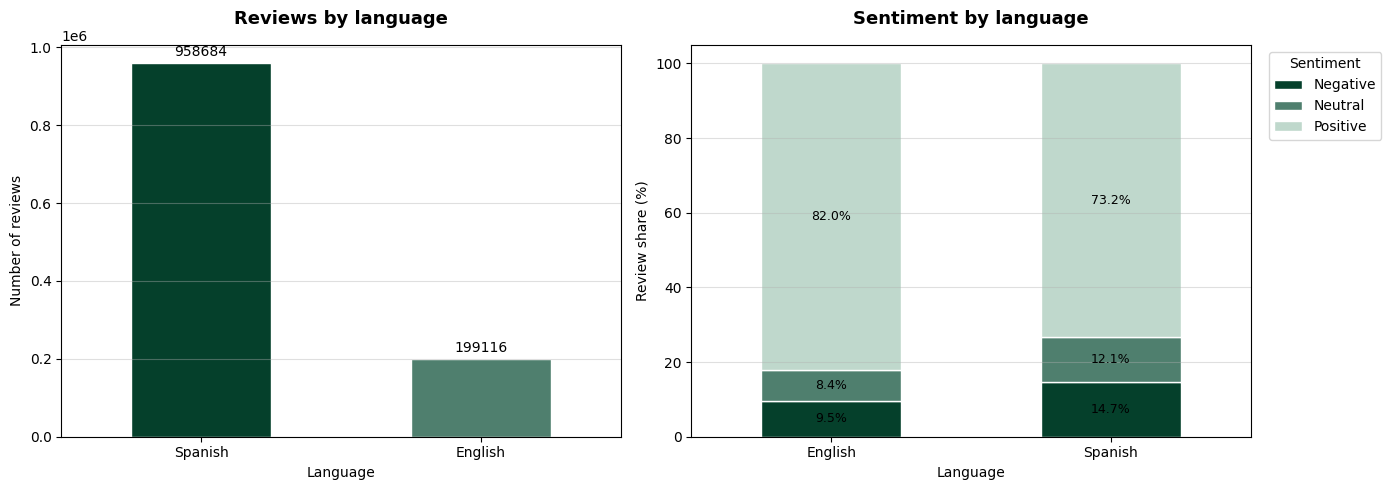

In [15]:
# 4.3. Reviews by source language label
sentiment_colors = [
    '#05402B',
    '#4F7F6E',
    '#BFD8CC'
]

language_colors = [
    '#05402B',
    '#4F7F6E'
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

language_summary_plot = language_summary.rename(
    index={
        'es': 'Spanish',
        'en': 'English'
    }
)

language_summary_plot['reviews'].plot(
    kind='bar',
    ax=axes[0],
    color=language_colors,
    edgecolor='white'
)

axes[0].set_title(
    'Reviews by language',
    fontsize=13,
    fontweight='bold',
    pad=15
)
axes[0].set_xlabel('Language')
axes[0].set_ylabel('Number of reviews')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', alpha=0.4)

for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

language_sentiment_plot = language_sentiment_percentage.rename(
    index={
        'es': 'Spanish',
        'en': 'English'
    }
)

language_sentiment_plot.plot(
    kind='bar',
    stacked=True,
    ax=axes[1],
    color=sentiment_colors,
    edgecolor='white'
)

axes[1].set_title(
    'Sentiment by language',
    fontsize=13,
    fontweight='bold',
    pad=15
)
axes[1].set_xlabel('Language')
axes[1].set_ylabel('Review share (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(
    title='Sentiment',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
axes[1].grid(axis='y', alpha=0.4)

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt='%.1f%%',
        label_type='center',
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [16]:
# 4.3. Reviews by source language label
chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    language_sentiment_counts
)

n_observations = language_sentiment_counts.to_numpy().sum()
n_rows, n_columns = language_sentiment_counts.shape

cramers_v = np.sqrt(
    (chi2 / n_observations)
    / min(n_rows - 1, n_columns - 1)
)

print(f'Chi-square: {chi2:,.2f}')
print(f'Degrees of freedom: {degrees_of_freedom}')
print('p-value:', '< 0.001' if p_value < 0.001 else f'{p_value:.3f}')
print(f'Cramér’s V: {cramers_v:.4f}')

Chi-square: 6,887.71
Degrees of freedom: 2
p-value: < 0.001
Cramér’s V: 0.0771


Spanish-labeled reviews make up 82.8% of the corpus, and English-labeled reviews 17.2%. Both groups have enough reviews for separate evaluation.

The Positive share is 82.05% in English-labeled reviews and 73.19% in Spanish-labeled reviews. Negative and Neutral labels are more common in the Spanish-labeled group.

Language label and sentiment are associated (`p < 0.001`), but the relationship is weak (Cramér’s V = 0.0771). A single bilingual classifier will be trained and evaluated for each source language label. These results do not show causation. Individual reviews may mix languages.


## 4.4. Review volume and reputation over time


### 4.4.1. Annual coverage


In [17]:
# 4.4.1. Annual coverage
data['review_year'] = data['date'].dt.year
data['year_month'] = data['date'].dt.to_period('M')

data['is_negative'] = (
    data['sentiment']
    .eq('Negative')
    .astype('int8')
)

In [18]:
# 4.4.1. Annual coverage
yearly_summary = (
    data
    .groupby('review_year')
    .agg(
        reviews=('review_id', 'size'),
        restaurants=('item_id', 'nunique'),
        mean_rating=('review_rating', 'mean'),
        negative_rate=('is_negative', 'mean')
    )
)

yearly_summary['negative_percentage'] = (
    yearly_summary['negative_rate']
    .mul(100)
)

yearly_summary = yearly_summary.drop(
    columns='negative_rate'
).round(2)

yearly_summary

,reviews,restaurants,mean_rating,negative_percentage
review_year,,,,
2002,1,1,5.0,0.00
2003,2,1,4.5,0.00
2004,1,1,4.0,0.00
2006,2,1,5.0,0.00
2007,333,108,3.88,7.81
2008,1371,303,3.71,13.35
2009,695,266,3.76,19.71
2010,1268,375,3.74,19.32
2011,4580,763,3.87,14.13


### 4.4.2. Complete monthly series


In [19]:
# 4.4.2. Complete monthly series
monthly_summary = (
    data
    .groupby('year_month')
    .agg(
        reviews=('review_id', 'size'),
        restaurants=('item_id', 'nunique'),
        rating_sum=('review_rating', 'sum'),
        negative_reviews=('is_negative', 'sum')
    )
)

complete_month_range = pd.period_range(
    start=data['year_month'].min(),
    end=data['year_month'].max(),
    freq='M'
)

monthly_summary = monthly_summary.reindex(
    complete_month_range
)

monthly_summary.index.name = 'year_month'

count_columns = [
    'reviews',
    'restaurants',
    'rating_sum',
    'negative_reviews'
]

monthly_summary[count_columns] = (
    monthly_summary[count_columns]
    .fillna(0)
)

monthly_summary['reviews'] = (
    monthly_summary['reviews']
    .astype('int64')
)

monthly_summary['restaurants'] = (
    monthly_summary['restaurants']
    .astype('int64')
)

monthly_summary['mean_rating'] = (
    monthly_summary['rating_sum']
    .div(monthly_summary['reviews'].replace(0, np.nan))
)

monthly_summary['negative_percentage'] = (
    monthly_summary['negative_reviews']
    .div(monthly_summary['reviews'].replace(0, np.nan))
    .mul(100)
)

monthly_summary = monthly_summary.reset_index()

monthly_summary['month'] = (
    monthly_summary['year_month']
    .dt.to_timestamp()
)

### 4.4.3. Exclude the last incomplete month


In [20]:
# 4.4.3. Exclude the last incomplete month
last_observed_date = data['date'].max()
last_complete_month = (
    last_observed_date.to_period('M') - 1
)

complete_monthly_summary = monthly_summary.loc[
    monthly_summary['year_month'] <= last_complete_month
].copy()

print(f'Last observed date: {last_observed_date.date()}')
print(f'Last complete month: {last_complete_month}')

Last observed date: 2023-06-10
Last complete month: 2023-05


### 4.4.4. Main period and 12-month moving trend


In [21]:
# 4.4.4. Main period and 12-month moving trend
minimum_annual_reviews = 10_000
minimum_annual_restaurants = 1_000

eligible_years = yearly_summary.loc[
    (yearly_summary['reviews'] >= minimum_annual_reviews)
    & (
        yearly_summary['restaurants']
        >= minimum_annual_restaurants
    )
].index

analysis_start_year = int(eligible_years.min())

temporal_summary = complete_monthly_summary.loc[
    complete_monthly_summary['month']
    >= pd.Timestamp(
        year=analysis_start_year,
        month=1,
        day=1
    )
].copy()

rolling_reviews = (
    temporal_summary['reviews']
    .rolling(window=12, min_periods=12)
    .sum()
)

rolling_rating_sum = (
    temporal_summary['rating_sum']
    .rolling(window=12, min_periods=12)
    .sum()
)

rolling_negative_reviews = (
    temporal_summary['negative_reviews']
    .rolling(window=12, min_periods=12)
    .sum()
)

temporal_summary['rolling_rating_12m'] = (
    rolling_rating_sum
    .div(rolling_reviews.replace(0, np.nan))
)

temporal_summary[
    'rolling_negative_percentage_12m'
] = (
    rolling_negative_reviews
    .div(rolling_reviews.replace(0, np.nan))
    .mul(100)
)

print(
    'First year with sufficient coverage:',
    analysis_start_year
)

First year with sufficient coverage: 2012


### 4.4.5. Charts over time


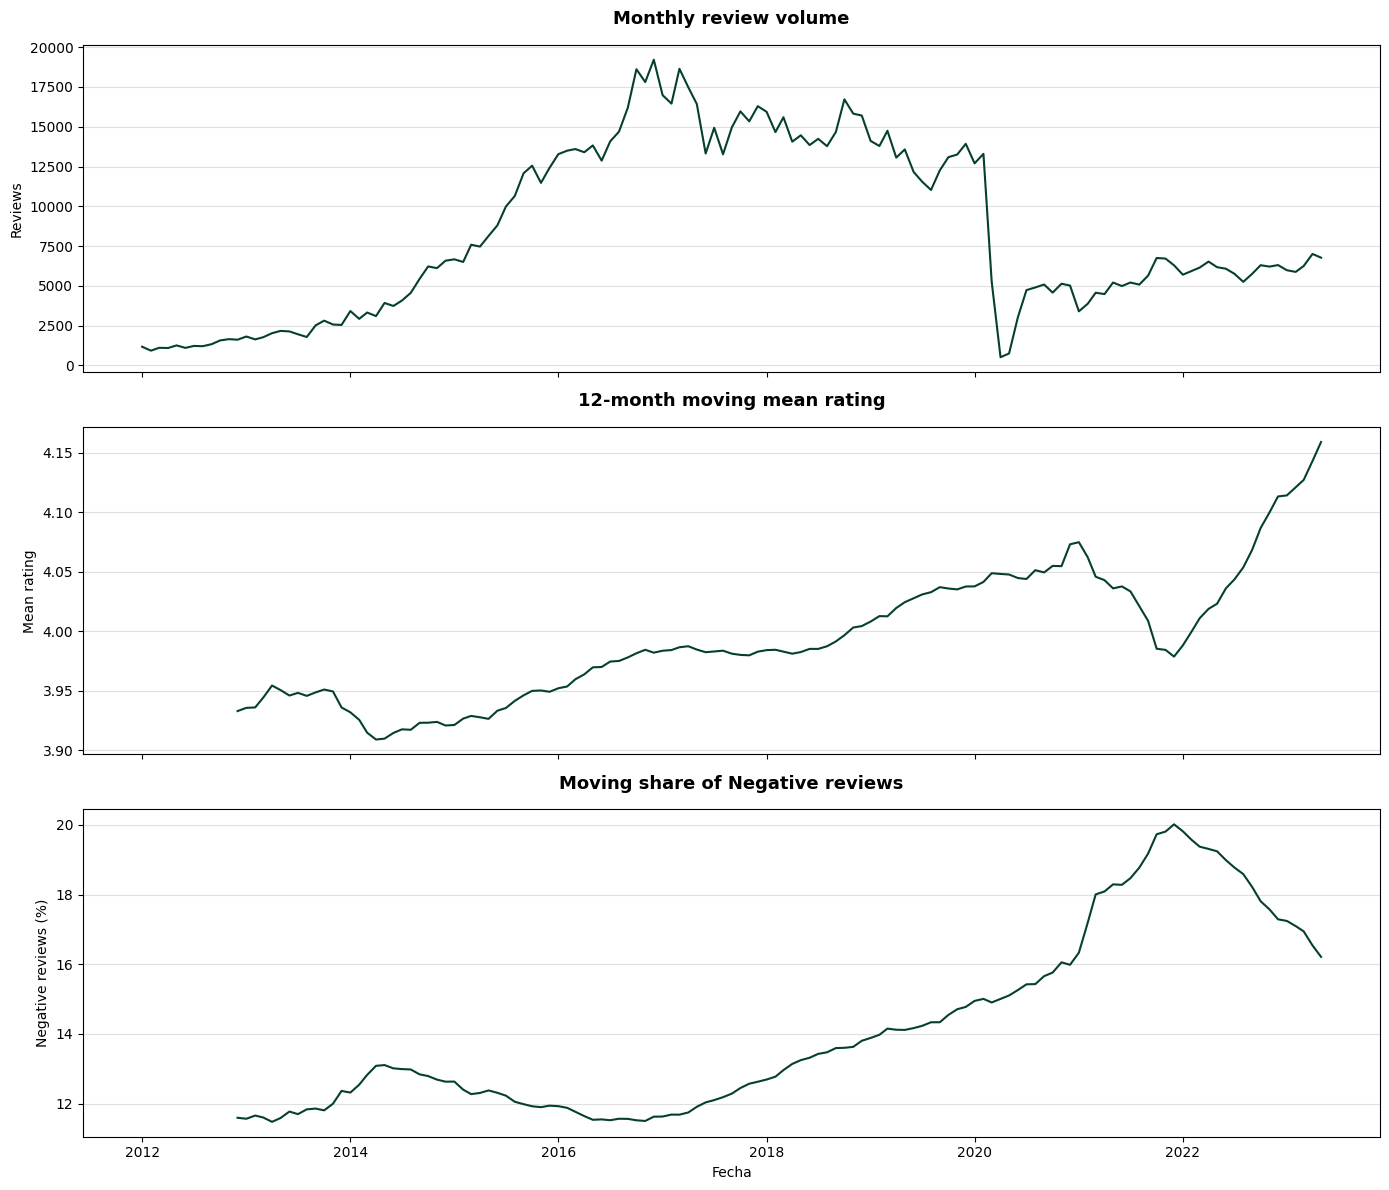

In [22]:
# 4.4.5. Charts over time
fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 12),
    sharex=True
)

axes[0].plot(
    temporal_summary['month'],
    temporal_summary['reviews'],
    color='#05402B'
)

axes[0].set_title(
    'Monthly review volume',
    fontsize=13,
    fontweight='bold',
    pad=15
)
axes[0].set_ylabel('Reviews')
axes[0].grid(axis='y', alpha=0.4)

axes[1].plot(
    temporal_summary['month'],
    temporal_summary['rolling_rating_12m'],
    color='#05402B'
)

axes[1].set_title(
    '12-month moving mean rating',
    fontsize=13,
    fontweight='bold',
    pad=15
)
axes[1].set_ylabel('Mean rating')
axes[1].grid(axis='y', alpha=0.4)

axes[2].plot(
    temporal_summary['month'],
    temporal_summary['rolling_negative_percentage_12m'],
    color='#05402B'
)

axes[2].set_title(
    'Moving share of Negative reviews',
    fontsize=13,
    fontweight='bold',
    pad=15
)
axes[2].set_xlabel('Fecha')
axes[2].set_ylabel('Negative reviews (%)')
axes[2].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

### Findings from the time analysis

- The main period starts in 2012. Earlier years remain in the data for traceability.
- Review volume reaches 190,086 in 2017 and drops by 58.5% in 2020 compared with 2019.
- In 2021 the mean rating falls to 3.98 and the Negative share rises to 20.01%. In 2022 they improve to 4.11 and 17.29%.
- June 2023 is incomplete; May is the last complete month.
- Mean rating and Negative share come from the same scores and are not independent evidence.

These are descriptive results; they do not establish causes.


## 4.5. Price range and reputation

Price ranges are examined by both number of restaurants and number of reviews. This prevents restaurants with many reviews from dominating a description of the available restaurants.

Keep `Unknown` to measure missing price information, but do not treat it as a real price range.

`price_interval` will be used to build competitive groups, not as an input to the sentiment classifier.


### 4.5.1. Build a unique restaurant catalog

Create one row per restaurant to describe the price distribution without giving extra weight to restaurants with many reviews.


In [23]:
# 4.5.1. Build a unique restaurant catalog
price_order = [
    'Budget',
    'Mid-range',
    'Premium',
    'Unknown'
]

restaurant_catalog = (
    data[
        [
            'item_id',
            'name',
            'price_interval',
            'restaurant_rating'
        ]
    ]
    .drop_duplicates(subset='item_id')
    .copy()
)

catalog_validation = pd.Series({
    'rows': len(restaurant_catalog),
    'unique_restaurants': (
        restaurant_catalog['item_id'].nunique()
    ),
    'duplicated_item_id': (
        restaurant_catalog['item_id'].duplicated().sum()
    ),
    'unknown_price': (
        restaurant_catalog['price_interval'].eq('Unknown').sum()
    )
}, name='result').to_frame()

catalog_validation

,result
rows,10056
unique_restaurants,10056
duplicated_item_id,0
unknown_price,2469


### 4.5.2. Restaurants by price range


In [24]:
# 4.5.2. Restaurants by price range
restaurant_price_summary = (
    restaurant_catalog['price_interval']
    .value_counts(sort=False)
    .reindex(price_order, fill_value=0)
    .rename_axis('price_interval')
    .to_frame('restaurants')
)

restaurant_price_summary['percentage'] = (
    restaurant_price_summary['restaurants']
    .div(restaurant_price_summary['restaurants'].sum())
    .mul(100)
    .round(2)
)

display(restaurant_price_summary)

print(
    'Total restaurants:',
    f"{restaurant_price_summary['restaurants'].sum():,}"
)

,restaurants,percentage
price_interval,,
Budget,2057,20.46
Mid-range,5202,51.73
Premium,328,3.26
Unknown,2469,24.55


Total restaurants: 10,056


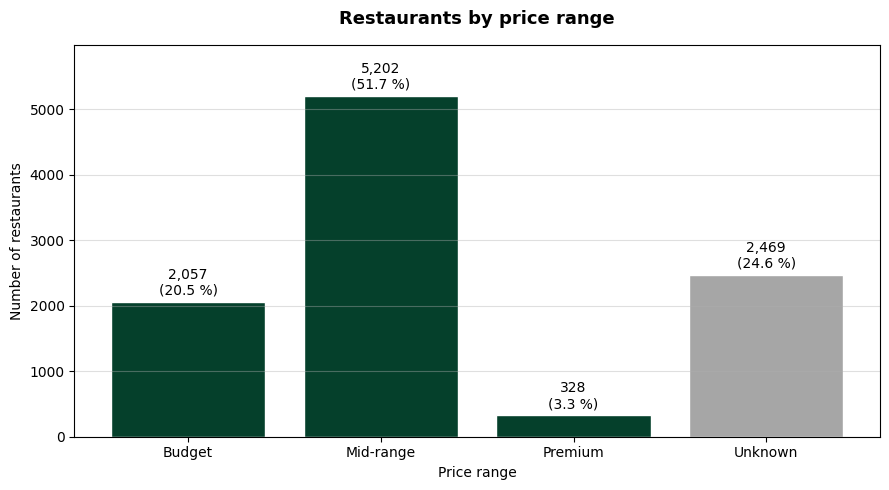

In [25]:
# 4.5.2. Restaurants by price range
price_plot = restaurant_price_summary.reset_index()

price_colors = [
    '#05402B',
    '#05402B',
    '#05402B',
    '#A6A6A6'
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    price_plot['price_interval'],
    price_plot['restaurants'],
    color=price_colors,
    edgecolor='white'
)

bar_labels = [
    f'{int(restaurants):,}\n({percentage:.1f} %)'
    for restaurants, percentage in zip(
        price_plot['restaurants'],
        price_plot['percentage']
    )
]

ax.bar_label(
    bars,
    labels=bar_labels,
    padding=3
)

ax.set_title(
    'Restaurants by price range',
    fontsize=13,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('Price range')
ax.set_ylabel('Number of restaurants')
ax.set_ylim(
    0,
    price_plot['restaurants'].max() * 1.15
)
ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

Mid-range has 5,202 restaurants (51.73%), Budget 2,057 (20.46%), and Premium 328 (3.26%).

Price is known for 7,587 restaurants (75.45%). The other 2,469 are labeled `Unknown`.

Premium remains in the analysis. Restaurants without a known price are included in the general analysis but excluded from comparisons by price.


### 4.5.3. Reviews by price range

Count reviews in each price range and calculate the mean and median number per restaurant to examine differences in activity.


In [26]:
# 4.5.3. Reviews by price range
reviews_per_restaurant = (
    data
    .groupby(
        ['price_interval', 'item_id'],
        observed=True
    )
    .size()
    .rename('reviews_per_restaurant')
    .reset_index()
)

review_price_summary = (
    reviews_per_restaurant
    .groupby('price_interval', observed=True)
    .agg(
        restaurants=('item_id', 'size'),
        reviews=('reviews_per_restaurant', 'sum'),
        mean_reviews_per_restaurant=(
            'reviews_per_restaurant',
            'mean'
        ),
        median_reviews_per_restaurant=(
            'reviews_per_restaurant',
            'median'
        )
    )
    .reindex(price_order)
)

review_price_summary['review_percentage'] = (
    review_price_summary['reviews']
    .div(review_price_summary['reviews'].sum())
    .mul(100)
)

review_price_summary = review_price_summary[
    [
        'restaurants',
        'reviews',
        'review_percentage',
        'mean_reviews_per_restaurant',
        'median_reviews_per_restaurant'
    ]
].round(2)

display(review_price_summary)

print(
    'Total reviews:',
    f"{int(review_price_summary['reviews'].sum()):,}"
)

,restaurants,reviews,review_percentage,mean_reviews_per_restaurant,median_reviews_per_restaurant
price_interval,,,,,
Budget,2057,148307,12.81,72.10,23.0
Mid-range,5202,881185,76.11,169.39,56.0
Premium,328,105637,9.12,322.06,142.0
Unknown,2469,22671,1.96,9.18,4.0


Total reviews: 1,157,800


### 4.5.4. Compare restaurant and review shares by price


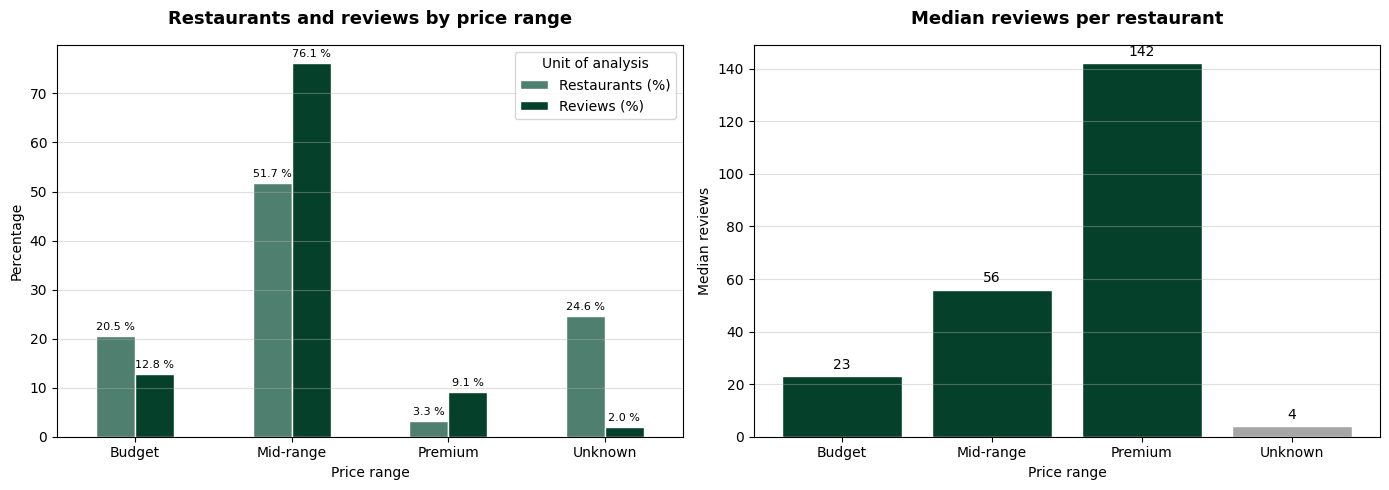

In [27]:
# 4.5.4. Compare restaurant and review shares by price
price_comparison = pd.DataFrame({
    'Restaurants (%)': (
        restaurant_price_summary['percentage']
    ),
    'Reviews (%)': (
        review_price_summary['review_percentage']
    )
}).reindex(price_order)

price_category_colors = [
    '#05402B',
    '#05402B',
    '#05402B',
    '#A6A6A6'
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

price_comparison.plot(
    kind='bar',
    ax=axes[0],
    color=['#4F7F6E', '#05402B'],
    edgecolor='white'
)

axes[0].set_title(
    'Restaurants and reviews by price range',
    fontsize=13,
    fontweight='bold',
    pad=15
)
axes[0].set_xlabel('Price range')
axes[0].set_ylabel('Percentage')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Unit of analysis')
axes[0].grid(axis='y', alpha=0.4)

for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt='%.1f %%',
        padding=3,
        fontsize=8
    )

median_activity = review_price_summary[
    'median_reviews_per_restaurant'
]

bars = axes[1].bar(
    median_activity.index,
    median_activity.values,
    color=price_category_colors,
    edgecolor='white'
)

axes[1].bar_label(
    bars,
    fmt='%.0f',
    padding=3
)

axes[1].set_title(
    'Median reviews per restaurant',
    fontsize=13,
    fontweight='bold',
    pad=15
)
axes[1].set_xlabel('Price range')
axes[1].set_ylabel('Median reviews')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

Mid-range accounts for 51.73% of restaurants and 76.11% of reviews. Premium accounts for 3.26% of restaurants and 9.12% of reviews; it has the highest median volume per restaurant (142).

`Unknown` covers 24.55% of restaurants but only 1.96% of reviews. Known prices cover 98.04% of reviews.

In each price range, the mean is higher than the median. Benchmarking therefore requires minimum group sizes and uses robust statistics. These differences are descriptive, not causal.


### 4.5.5. Sentiment by price range

Use only restaurants with known prices. Calculate percentages within each range so that differences in review volume do not dominate the comparison.


In [28]:
# 4.5.5. Sentiment by price range
known_price_order = [
    'Budget',
    'Mid-range',
    'Premium'
]

known_price_data = data.loc[
    data['price_interval'].isin(known_price_order)
].copy()

price_sentiment_counts = (
    pd.crosstab(
        known_price_data['price_interval'],
        known_price_data['sentiment']
    )
    .reindex(
        index=known_price_order,
        columns=sentiment_order
    )
)

price_sentiment_percentage = (
    pd.crosstab(
        known_price_data['price_interval'],
        known_price_data['sentiment'],
        normalize='index'
    )
    .mul(100)
    .reindex(
        index=known_price_order,
        columns=sentiment_order
    )
    .round(2)
)

display(price_sentiment_counts)
display(price_sentiment_percentage)

known_price_reviews = (
    price_sentiment_counts
    .to_numpy()
    .sum()
)

print(
    'Reviews with known price:',
    f'{known_price_reviews:,}'
)

print(
    'Coverage of total:',
    f'{known_price_reviews / len(data) * 100:.2f} %'
)

sentiment,Negative,Neutral,Positive
price_interval,,,
Budget,22440,18338,107529
Mid-range,121070,100542,659573
Premium,12622,12001,81014


sentiment,Negative,Neutral,Positive
price_interval,,,
Budget,15.13,12.36,72.50
Mid-range,13.74,11.41,74.85
Premium,11.95,11.36,76.69


Reviews with known price: 1,135,129
Coverage of total: 98.04 %


### 4.5.6. Chart sentiment by price range


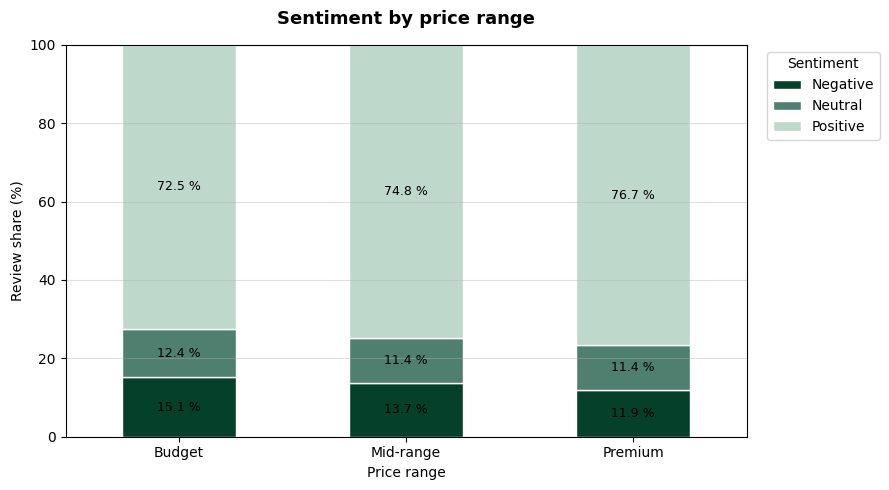

In [29]:
# 4.5.6. Chart sentiment by price range
fig, ax = plt.subplots(figsize=(9, 5))

price_sentiment_percentage.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=sentiment_colors,
    edgecolor='white'
)

ax.set_title(
    'Sentiment by price range',
    fontsize=13,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('Price range')
ax.set_ylabel('Review share (%)')
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=0)
ax.legend(
    title='Sentiment',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
ax.grid(axis='y', alpha=0.4)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f %%',
        label_type='center',
        fontsize=9
    )


plt.tight_layout()


plt.show()

### 4.5.7. Statistical association between price and sentiment


In [30]:
# 4.5.7. Statistical association between price and sentiment
chi2, p_value, degrees_of_freedom, expected = (
    chi2_contingency(price_sentiment_counts)
)

n_observations = price_sentiment_counts.to_numpy().sum()
n_rows, n_columns = price_sentiment_counts.shape

cramers_v = np.sqrt(
    (chi2 / n_observations)
    / min(n_rows - 1, n_columns - 1)
)

print(f'Chi-square: {chi2:,.2f}')
print(f'Degrees of freedom: {degrees_of_freedom}')
print(
    'p-value:',
    '< 0.001' if p_value < 0.001
    else f'{p_value:.3f}'
)
print(f'Cramér’s V: {cramers_v:.4f}')
print(
    'Minimum expected frequency:',
    f'{expected.min():,.2f}'
)

Chi-square: 712.58
Degrees of freedom: 4
p-value: < 0.001
Cramér’s V: 0.0177
Minimum expected frequency: 12,180.00


The Negative share falls from 15.13% in Budget to 11.95% in Premium; the Positive share rises from 72.50% to 76.69%.

The association is statistically significant (`p < 0.001`) but very weak (Cramér’s V = 0.0177). Price is used for benchmarking, not as a classifier input.

Because `sentiment` is derived from `review_rating`, this result describes a proxy label and does not establish causation.


## 4.6. Cuisine types

`type` is a list: a restaurant may belong to several cuisine types. The total number of restaurant–cuisine assignments can therefore exceed the number of restaurants.

Start with one row per restaurant. Exploding the review table itself would duplicate reviews of restaurants with several cuisine types and distort results.


### 4.6.1. Validate the cuisine lists


In [31]:
# 4.6.1. Validate the cuisine lists
restaurant_specialty_catalog = (
    data[
        [
            'item_id',
            'name',
            'price_interval',
            'restaurant_rating',
            'type'
        ]
    ]
    .drop_duplicates(subset='item_id')
    .copy()
)

is_list = restaurant_specialty_catalog['type'].map(
    lambda values: isinstance(values, list)
)

specialty_count = restaurant_specialty_catalog['type'].map(
    lambda values: len(values)
    if isinstance(values, list)
    else 0
)

specialty_validation = pd.Series({
    'restaurants': len(restaurant_specialty_catalog),
    'unique_restaurants': (
        restaurant_specialty_catalog['item_id'].nunique()
    ),
    'non_list_values': (~is_list).sum(),
    'empty_lists': specialty_count.eq(0).sum(),
    'restaurants_without_specialty_information': (
        restaurant_specialty_catalog['type']
        .map(
            lambda values: (
                'Unknown' in values
                if isinstance(values, list)
                else False
            )
        )
        .sum()
    ),
    'total_specialty_assignments': specialty_count.sum(),
    'mean_specialties_per_restaurant': specialty_count.mean(),
    'restaurants_with_repeated_specialty': (
        restaurant_specialty_catalog['type']
        .map(
            lambda values: (
                len(values) != len(set(values))
                if isinstance(values, list)
                else False
            )
        )
        .sum()
    )
}, name='result').to_frame()

specialty_validation.round(2)

,result
restaurants,10056.00
unique_restaurants,10056.00
non_list_values,0.00
empty_lists,0.00
restaurants_without_specialty_information,1172.00
total_specialty_assignments,16278.00
mean_specialties_per_restaurant,1.62
restaurants_with_repeated_specialty,0.00


### 4.6.2. Expand cuisine types per restaurant

Create a separate table with one restaurant–cuisine pair per row. Keep the original review dataset unchanged.


In [32]:
# 4.6.2. Expand cuisine types per restaurant
restaurant_specialty = (
    restaurant_specialty_catalog
    .explode(
        column='type',
        ignore_index=True
    )
    .rename(columns={'type': 'specialty'})
)

restaurant_specialty['specialty'] = (
    restaurant_specialty['specialty']
    .astype('string')
    .str.strip()
)

expanded_specialty_validation = pd.Series({
    'rows': len(restaurant_specialty),
    'unique_restaurants': (
        restaurant_specialty['item_id'].nunique()
    ),
    'missing_specialty': (
        restaurant_specialty['specialty'].isna().sum()
    ),
    'empty_specialty': (
        restaurant_specialty['specialty'].eq('').sum()
    ),
    'duplicated_restaurant_specialty': (
        restaurant_specialty
        .duplicated(
            subset=['item_id', 'specialty']
        )
        .sum()
    ),
    'assignments_without_information': (
        restaurant_specialty['specialty']
        .eq('Unknown')
        .sum()
    )
}, name='result').to_frame()

expanded_specialty_validation

,result
rows,16278
unique_restaurants,10056
missing_specialty,0
empty_specialty,0
duplicated_restaurant_specialty,0
assignments_without_information,1172


### 4.6.3. Restaurants by cuisine type

Exclude `Unknown` from the ranking because it is not a cuisine type. Count unique restaurants rather than reviews.


In [33]:
# 4.6.3. Restaurants by cuisine type
known_restaurant_specialty = (
    restaurant_specialty.loc[
        restaurant_specialty['specialty']
        .ne('Unknown')
    ]
    .copy()
)

known_specialty_restaurants = (
    known_restaurant_specialty['item_id']
    .nunique()
)

specialty_summary = (
    known_restaurant_specialty
    .groupby('specialty')
    .agg(
        restaurants=('item_id', 'nunique')
    )
    .sort_values(
        by='restaurants',
        ascending=False
    )
)

specialty_summary[
    'percentage_known_restaurants'
] = (
    specialty_summary['restaurants']
    .div(known_specialty_restaurants)
    .mul(100)
    .round(2)
)

display(specialty_summary.head(20))

print(
    'Distinct cuisine types:',
    f'{len(specialty_summary):,}'
)

print(
    'Restaurants with known cuisine:',
    f'{known_specialty_restaurants:,}'
)

print(
    'Known cuisine assignments:',
    f'{len(known_restaurant_specialty):,}'
)

,restaurants,percentage_known_restaurants
specialty,,
Spanish,3615,40.69
Mediterranean,2447,27.54
Cafe,806,9.07
European,686,7.72
Bar,653,7.35
Italian,575,6.47
American,460,5.18
Coffee & Tea,392,4.41
Japanese,379,4.27


Distinct cuisine types: 113
Restaurants with known cuisine: 8,884
Known cuisine assignments: 15,106


### 4.6.4. Most common cuisine types


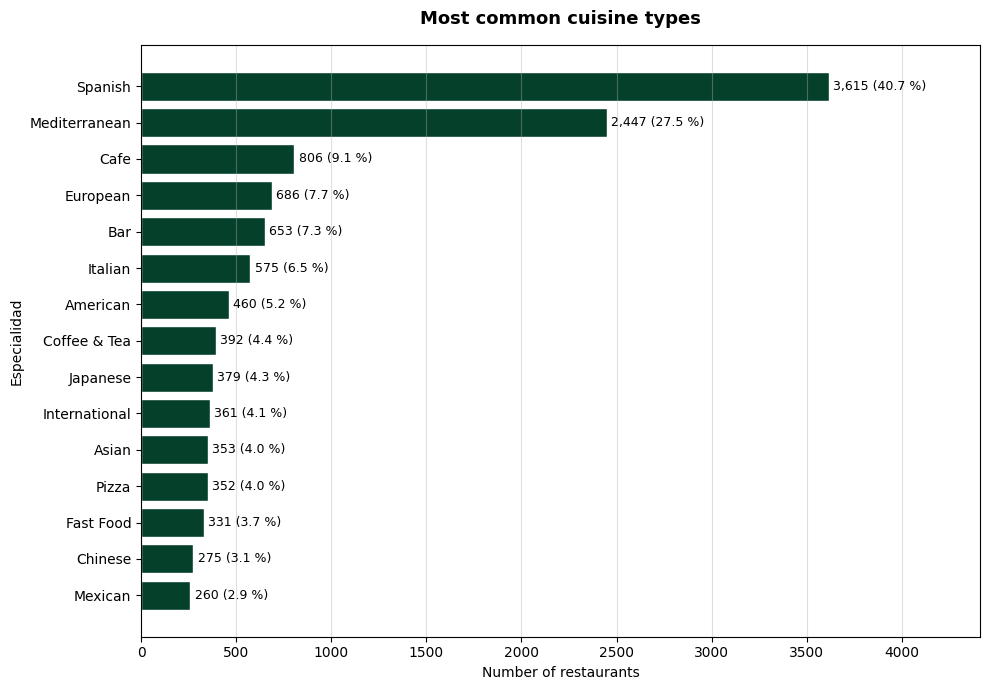

In [34]:
# 4.6.4. Most common cuisine types
top_n_specialties = 15

top_specialties = (
    specialty_summary
    .head(top_n_specialties)
    .sort_values(
        by='restaurants',
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    top_specialties.index,
    top_specialties['restaurants'],
    color='#05402B',
    edgecolor='white'
)

bar_labels = [
    f'{int(restaurants):,} ({percentage:.1f} %)'
    for restaurants, percentage in zip(
        top_specialties['restaurants'],
        top_specialties[
            'percentage_known_restaurants'
        ]
    )
]

ax.bar_label(
    bars,
    labels=bar_labels,
    padding=3,
    fontsize=9
)

ax.set_title(
    'Most common cuisine types',
    fontsize=13,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('Number of restaurants')
ax.set_ylabel('Especialidad')
ax.set_xlim(
    0,
    top_specialties['restaurants'].max() * 1.22
)
ax.grid(axis='x', alpha=0.4)

plt.tight_layout()


plt.show()

There are 113 cuisine types across 8,884 restaurants. `Spanish` appears in 3,615 (40.69%) and `Mediterranean` in 2,447 (27.54%).

Cuisine types overlap, so percentages do not add up to 100%. The chart shows the top 15 while the analysis keeps the full list.

Small groups need minimum restaurant and review counts before they can be used for benchmarking.


### 4.6.5. Competitive group support

Groups combine cuisine type and price range. First count reviews per restaurant, then join these counts to the cuisine table. A restaurant may contribute to several cuisine groups, but its reviews are counted only once within each group.


In [35]:
# 4.6.5. Competitive group support
restaurant_activity = (
    data
    .groupby(
        'item_id',
        as_index=False
    )
    .agg(
        reviews=('review_id', 'size')
    )
)

benchmark_membership = (
    known_restaurant_specialty.loc[
        known_restaurant_specialty[
            'price_interval'
        ].isin(known_price_order),
        [
            'item_id',
            'specialty',
            'price_interval'
        ]
    ]
    .merge(
        restaurant_activity,
        on='item_id',
        how='left',
        validate='many_to_one'
    )
)

benchmark_group_support = (
    benchmark_membership
    .groupby(
        [
            'specialty',
            'price_interval'
        ],
        observed=True
    )
    .agg(
        restaurants=('item_id', 'nunique'),
        reviews=('reviews', 'sum')
    )
    .reset_index()
    .sort_values(
        by=[
            'restaurants',
            'reviews'
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

benchmark_support_validation = pd.Series({
    'membership_rows': len(benchmark_membership),
    'unique_restaurants': (
        benchmark_membership['item_id'].nunique()
    ),
    'competitive_groups': (
        len(benchmark_group_support)
    ),
    'missing_review_counts': (
        benchmark_membership['reviews'].isna().sum()
    ),
    'duplicated_memberships': (
        benchmark_membership
        .duplicated(
            subset=[
                'item_id',
                'specialty',
                'price_interval'
            ]
        )
        .sum()
    )
}, name='result').to_frame()

display(benchmark_support_validation)
display(benchmark_group_support.head(20))

display(
    benchmark_group_support[
        ['restaurants', 'reviews']
    ]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95
        ]
    )
    .round(2)
)

,result
membership_rows,12607
unique_restaurants,7232
competitive_groups,219
missing_review_counts,0
duplicated_memberships,0


,specialty,price_interval,restaurants,reviews
0,Spanish,Mid-range,2128,252049
1,Mediterranean,Mid-range,1782,408201
2,Spanish,Budget,724,32923
3,European,Mid-range,511,198476
4,Italian,Mid-range,355,68451
5,Bar,Mid-range,333,81560
6,Cafe,Budget,315,32122
7,Cafe,Mid-range,314,42509
8,Mediterranean,Budget,294,42086
9,American,Mid-range,269,57068


,restaurants,reviews
count,219.00,219.00
mean,57.57,9615.16
std,202.93,36739.41
min,1.00,1.00
10%,1.00,18.00
25%,1.50,94.00
50%,6.00,572.00
75%,30.00,3417.50
90%,138.40,23224.40
95%,237.80,42128.30


### 4.6.6. Compare benchmarking thresholds

Compare three minimum group sizes. Select a rule using both the number of available groups and the coverage of restaurants and reviews.


In [36]:
# 4.6.6. Compare benchmarking thresholds
benchmark_restaurant_ids = (
    benchmark_membership['item_id']
    .drop_duplicates()
)

benchmark_restaurant_activity = (
    restaurant_activity.loc[
        restaurant_activity['item_id']
        .isin(benchmark_restaurant_ids)
    ]
    .copy()
)

benchmark_total_restaurants = (
    benchmark_restaurant_activity['item_id']
    .nunique()
)

benchmark_total_reviews = (
    benchmark_restaurant_activity['reviews']
    .sum()
)

threshold_options = [
    {
        'criterion': 'Flexible',
        'minimum_restaurants': 10,
        'minimum_reviews': 500
    },
    {
        'criterion': 'Balanced',
        'minimum_restaurants': 30,
        'minimum_reviews': 1_000
    },
    {
        'criterion': 'Conservative',
        'minimum_restaurants': 50,
        'minimum_reviews': 2_000
    }
]

threshold_results = []

for option in threshold_options:
    eligible_groups = benchmark_group_support.loc[
        (
            benchmark_group_support['restaurants']
            >= option['minimum_restaurants']
        )
        & (
            benchmark_group_support['reviews']
            >= option['minimum_reviews']
        )
    ].copy()

    eligible_membership = benchmark_membership.merge(
        eligible_groups[
            ['specialty', 'price_interval']
        ],
        on=['specialty', 'price_interval'],
        how='inner',
        validate='many_to_one'
    )

    covered_restaurant_ids = (
        eligible_membership['item_id']
        .drop_duplicates()
    )

    covered_reviews = (
        benchmark_restaurant_activity.loc[
            benchmark_restaurant_activity['item_id']
            .isin(covered_restaurant_ids),
            'reviews'
        ]
        .sum()
    )

    threshold_results.append({
        'criterion': option['criterion'],
        'minimum_restaurants': (
            option['minimum_restaurants']
        ),
        'minimum_reviews': (
            option['minimum_reviews']
        ),
        'eligible_groups': len(eligible_groups),
        'eligible_specialties': (
            eligible_groups['specialty'].nunique()
        ),
        'covered_restaurants': (
            covered_restaurant_ids.nunique()
        ),
        'restaurant_coverage_percentage': (
            covered_restaurant_ids.nunique()
            / benchmark_total_restaurants
            * 100
        ),
        'covered_reviews': covered_reviews,
        'review_coverage_percentage': (
            covered_reviews
            / benchmark_total_reviews
            * 100
        )
    })

threshold_comparison = (
    pd.DataFrame(threshold_results)
    .set_index('criterion')
    .round(2)
)

threshold_comparison

,minimum_restaurants,minimum_reviews,eligible_groups,eligible_specialties,covered_restaurants,restaurant_coverage_percentage,covered_reviews,review_coverage_percentage
criterion,,,,,,,,
Flexible,10,500,87,48,7159,98.99,1112923,99.30
Balanced,30,1000,55,32,6996,96.74,1098034,97.97
Conservative,50,2000,45,26,6880,95.13,1083898,96.71


### 4.6.7. Select the final threshold


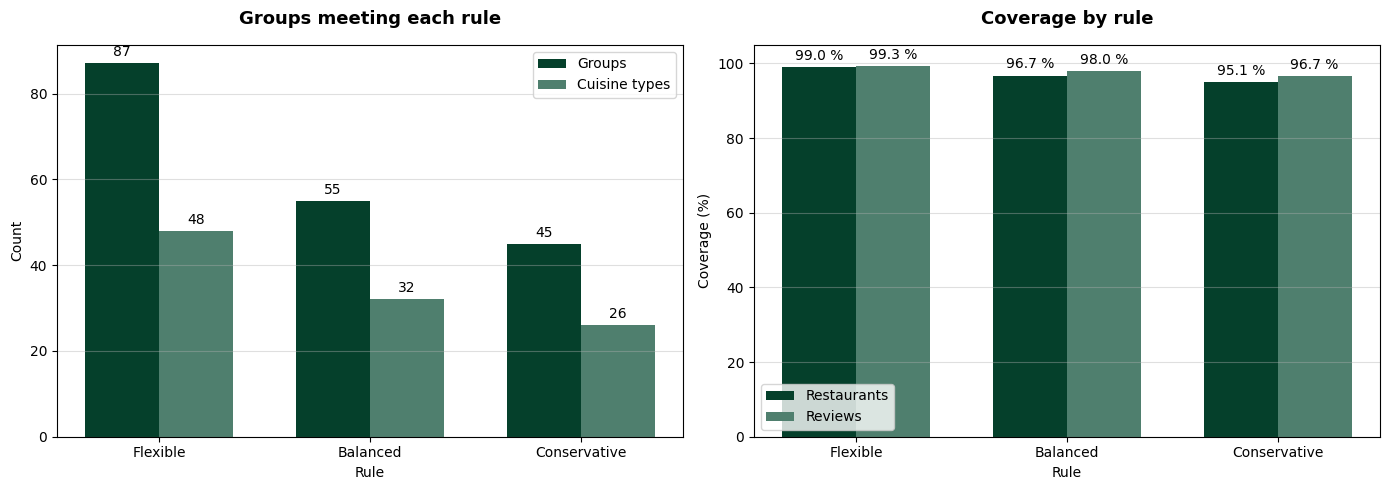

In [37]:
# 4.6.7. Select the final threshold
threshold_plot = threshold_comparison.reset_index()

x_positions = np.arange(len(threshold_plot))
bar_width = 0.35

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

group_bars = axes[0].bar(
    x_positions - bar_width / 2,
    threshold_plot['eligible_groups'],
    width=bar_width,
    label='Groups',
    color='#05402B'
)

specialty_bars = axes[0].bar(
    x_positions + bar_width / 2,
    threshold_plot['eligible_specialties'],
    width=bar_width,
    label='Cuisine types',
    color='#4F7F6E'
)

axes[0].bar_label(group_bars, padding=3)
axes[0].bar_label(specialty_bars, padding=3)

axes[0].set_title(
    'Groups meeting each rule',
    fontsize=13,
    fontweight='bold',
    pad=15
)
axes[0].set_xticks(
    x_positions,
    threshold_plot['criterion']
)
axes[0].set_xlabel('Rule')
axes[0].set_ylabel('Count')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.4)

restaurant_bars = axes[1].bar(
    x_positions - bar_width / 2,
    threshold_plot[
        'restaurant_coverage_percentage'
    ],
    width=bar_width,
    label='Restaurants',
    color='#05402B'
)

review_bars = axes[1].bar(
    x_positions + bar_width / 2,
    threshold_plot[
        'review_coverage_percentage'
    ],
    width=bar_width,
    label='Reviews',
    color='#4F7F6E'
)

axes[1].bar_label(
    restaurant_bars,
    fmt='%.1f %%',
    padding=3
)
axes[1].bar_label(
    review_bars,
    fmt='%.1f %%',
    padding=3
)

axes[1].set_title(
    'Coverage by rule',
    fontsize=13,
    fontweight='bold',
    pad=15
)
axes[1].set_xticks(
    x_positions,
    threshold_plot['criterion']
)
axes[1].set_xlabel('Rule')
axes[1].set_ylabel('Coverage (%)')
axes[1].set_ylim(0, 105)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.4)

plt.tight_layout()


plt.show()

In [38]:
# 4.6.7. Select the final threshold
minimum_benchmark_restaurants = 30
minimum_benchmark_reviews = 1_000

eligible_benchmark_groups = (
    benchmark_group_support.loc[
        (
            benchmark_group_support['restaurants']
            >= minimum_benchmark_restaurants
        )
        & (
            benchmark_group_support['reviews']
            >= minimum_benchmark_reviews
        )
    ]
    .copy()
    .rename(
        columns={
            'restaurants': 'group_restaurants',
            'reviews': 'group_reviews'
        }
    )
)

eligible_benchmark_groups['benchmark_group'] = (
    eligible_benchmark_groups['specialty']
    .astype('string')
    + ' | '
    + eligible_benchmark_groups['price_interval']
    .astype('string')
)

eligible_benchmark_membership = (
    benchmark_membership
    .merge(
        eligible_benchmark_groups[
            [
                'specialty',
                'price_interval',
                'benchmark_group',
                'group_restaurants',
                'group_reviews'
            ]
        ],
        on=[
            'specialty',
            'price_interval'
        ],
        how='inner',
        validate='many_to_one'
    )
)

selected_restaurant_ids = (
    eligible_benchmark_membership['item_id']
    .drop_duplicates()
)

selected_covered_reviews = (
    benchmark_restaurant_activity.loc[
        benchmark_restaurant_activity['item_id']
        .isin(selected_restaurant_ids),
        'reviews'
    ]
    .sum()
)

selected_benchmark_validation = pd.Series({
    'eligible_groups': len(eligible_benchmark_groups),
    'eligible_specialties': (
        eligible_benchmark_groups['specialty'].nunique()
    ),
    'covered_restaurants': (
        selected_restaurant_ids.nunique()
    ),
    'restaurant_coverage_percentage': (
        selected_restaurant_ids.nunique()
        / benchmark_total_restaurants
        * 100
    ),
    'covered_reviews': selected_covered_reviews,
    'review_coverage_percentage': (
        selected_covered_reviews
        / benchmark_total_reviews
        * 100
    )
}, name='result').to_frame()

selected_benchmark_validation.round(2)

,result
eligible_groups,55.00
eligible_specialties,32.00
covered_restaurants,6996.00
restaurant_coverage_percentage,96.74
covered_reviews,1098034.00
review_coverage_percentage,97.97


Choose the Balanced rule: at least 30 restaurants and 1,000 reviews per cuisine type and price range. It retains 55 groups across 32 cuisine types, covering 96.74% of comparable restaurants and 97.97% of their reviews.

These thresholds are operational rules for group support. A restaurant with several cuisine types may belong to several groups.


## 4.7. Restaurant-level reputation diagnosis

Aggregate reviews for each restaurant: volume, mean rating, rating spread, sentiment shares, and time coverage.

Both `sentiment` and `review_rating` come from the same rating and are not independent measures of reputation. Five source restaurant ratings remain missing; the review-based measures are still available.


### 4.7.1. Build restaurant-level indicators


In [39]:
# 4.7.1. Build restaurant-level indicators
data['is_neutral'] = (
    data['sentiment']
    .eq('Neutral')
    .astype('int8')
)

data['is_positive'] = (
    data['sentiment']
    .eq('Positive')
    .astype('int8')
)

restaurant_reputation = (
    data
    .groupby(
        'item_id',
        as_index=False,
        observed=True
    )
    .agg(
        name=('name', 'first'),
        price_interval=('price_interval', 'first'),
        platform_rating=('restaurant_rating', 'first'),
        reviews=('review_id', 'size'),
        first_review_date=('date', 'min'),
        last_review_date=('date', 'max'),
        mean_review_rating=('review_rating', 'mean'),
        median_review_rating=('review_rating', 'median'),
        rating_std=('review_rating', 'std'),
        negative_reviews=('is_negative', 'sum'),
        neutral_reviews=('is_neutral', 'sum'),
        positive_reviews=('is_positive', 'sum')
    )
)

restaurant_reputation['negative_percentage'] = (
    restaurant_reputation['negative_reviews']
    .div(restaurant_reputation['reviews'])
    .mul(100)
)

restaurant_reputation['neutral_percentage'] = (
    restaurant_reputation['neutral_reviews']
    .div(restaurant_reputation['reviews'])
    .mul(100)
)

restaurant_reputation['positive_percentage'] = (
    restaurant_reputation['positive_reviews']
    .div(restaurant_reputation['reviews'])
    .mul(100)
)

restaurant_reputation['review_span_days'] = (
    restaurant_reputation['last_review_date']
    - restaurant_reputation['first_review_date']
).dt.days

In [40]:
reputation_validation = pd.Series({
    'restaurants': len(restaurant_reputation),
    'unique_restaurants': (
        restaurant_reputation['item_id'].nunique()
    ),
    'total_reviews': (
        restaurant_reputation['reviews'].sum()
    ),
    'total_sentiment_assignments': (
        restaurant_reputation[
            [
                'negative_reviews',
                'neutral_reviews',
                'positive_reviews'
            ]
        ]
        .sum()
        .sum()
    ),
    'missing_mean_rating': (
        restaurant_reputation[
            'mean_review_rating'
        ]
        .isna()
        .sum()
    ),
    'restaurants_with_one_review': (
        restaurant_reputation['reviews']
        .eq(1)
        .sum()
    ),
    'missing_rating_std': (
        restaurant_reputation['rating_std']
        .isna()
        .sum()
    )
}, name='result').to_frame()

display(reputation_validation)

reputation_distribution = (
    restaurant_reputation[
        [
            'reviews',
            'mean_review_rating',
            'rating_std',
            'negative_percentage',
            'positive_percentage',
            'review_span_days'
        ]
    ]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .T
    .round(2)
)

reputation_distribution

,result
restaurants,10056
unique_restaurants,10056
total_reviews,1157800
total_sentiment_assignments,1157800
missing_mean_rating,0
restaurants_with_one_review,692
missing_rating_std,692


,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
reviews,10056.0,115.135243,411.042544,1.0,2.0,7.0,25.0,91.0,277.5,491.25,1295.15,22679.0
mean_review_rating,10056.0,3.817122,0.821724,1.0,2.736842,3.357143,3.954397,4.40253,4.833333,5.0,5.0,5.0
rating_std,9364.0,1.157799,0.478734,0.0,0.52182,0.915641,1.220851,1.461963,1.666799,1.82201,2.309401,2.828427
negative_percentage,10056.0,19.596903,21.096832,0.0,0.0,3.447176,13.636364,28.571429,50.0,62.092265,100.0,100.0
positive_percentage,10056.0,68.957983,25.352722,0.0,33.333333,52.941176,73.429705,88.888889,100.0,100.0,100.0,100.0
review_span_days,10056.0,1890.821897,1417.771178,0.0,92.5,651.0,1755.5,2879.0,3788.0,4398.5,5585.35,7514.0


The review counts are uneven: the median is 25, the mean is about 115, and the maximum is 22,679. The 692 missing `rating_std` values belong to restaurants with only one review. Do not replace them with zero. Group restaurants by the amount of evidence available without removing them.


### 4.7.2. Diagnosis support level

Group restaurants by their review counts. This keeps every restaurant while making the amount of evidence clear.


In [41]:
# 4.7.2. Diagnosis support level
support_labels = [
    'Very low (1-9)',
    'Low (10-29)',
    'Adequate (30-99)',
    'High (100 or more)'
]

restaurant_reputation['diagnostic_support'] = pd.cut(
    restaurant_reputation['reviews'],
    bins=[
        0,
        9,
        29,
        99,
        np.inf
    ],
    labels=support_labels,
    include_lowest=True,
    ordered=True
)

diagnostic_support_summary = (
    restaurant_reputation
    .groupby(
        'diagnostic_support',
        observed=False
    )
    .agg(
        restaurants=('item_id', 'size'),
        reviews=('reviews', 'sum'),
        mean_reviews=('reviews', 'mean'),
        median_reviews=('reviews', 'median')
    )
)

diagnostic_support_summary[
    'restaurant_percentage'
] = (
    diagnostic_support_summary['restaurants']
    .div(diagnostic_support_summary['restaurants'].sum())
    .mul(100)
)

diagnostic_support_summary[
    'review_percentage'
] = (
    diagnostic_support_summary['reviews']
    .div(diagnostic_support_summary['reviews'].sum())
    .mul(100)
)

diagnostic_support_summary = (
    diagnostic_support_summary[
        [
            'restaurants',
            'restaurant_percentage',
            'reviews',
            'review_percentage',
            'mean_reviews',
            'median_reviews'
        ]
    ]
    .round(2)
)

display(diagnostic_support_summary)

print(
    'Total restaurants:',
    f"{diagnostic_support_summary['restaurants'].sum():,}"
)

print(
    'Total reviews:',
    f"{diagnostic_support_summary['reviews'].sum():,}"
)

,restaurants,restaurant_percentage,reviews,review_percentage,mean_reviews,median_reviews
diagnostic_support,,,,,,
Very low (1-9),3062,30.45,12207,1.05,3.99,4.0
Low (10-29),2324,23.11,41679,3.60,17.93,17.0
Adequate (30-99),2305,22.92,128836,11.13,55.89,52.0
High (100 or more),2365,23.52,975078,84.22,412.30,239.0


Total restaurants: 10,056
Total reviews: 1,157,800


### 4.7.3. Coverage by support level


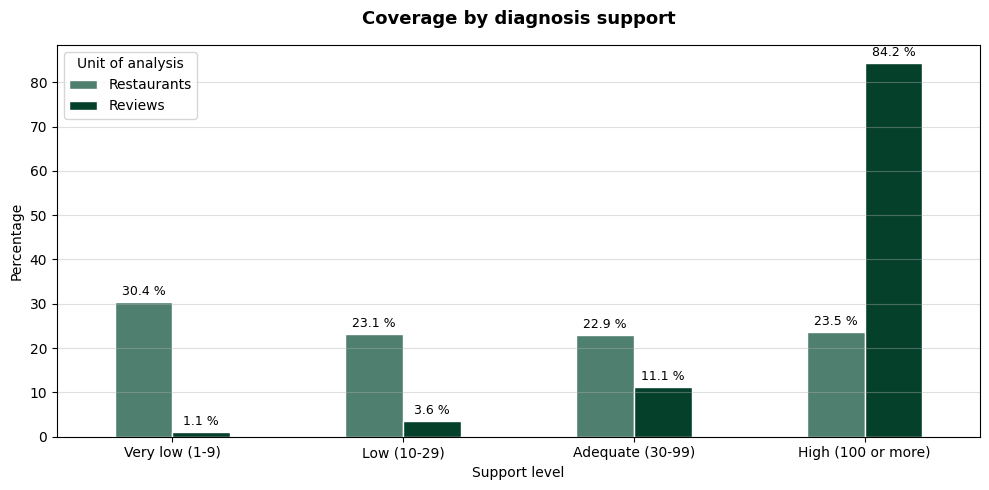

In [42]:
# 4.7.3. Coverage by support level
diagnostic_support_plot = (
    diagnostic_support_summary[
        [
            'restaurant_percentage',
            'review_percentage'
        ]
    ]
    .rename(
        columns={
            'restaurant_percentage': 'Restaurants',
            'review_percentage': 'Reviews'
        }
    )
)

ax = diagnostic_support_plot.plot(
    kind='bar',
    figsize=(10, 5),
    color=['#4F7F6E', '#05402B'],
    edgecolor='white'
)

ax.set_title(
    'Coverage by diagnosis support',
    fontsize=13,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('Support level')
ax.set_ylabel('Percentage')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Unit of analysis')
ax.grid(axis='y', alpha=0.4)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f %%',
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

**Assign the final diagnosis status**


In [43]:
# **Assign the final diagnosis status**
diagnostic_status_order = [
    'Insufficient data',
    'Limited diagnosis',
    'Full diagnosis'
]

restaurant_reputation['diagnostic_status'] = np.select(
    [
        restaurant_reputation['reviews'].ge(30),
        restaurant_reputation['reviews'].ge(10)
    ],
    [
        'Full diagnosis',
        'Limited diagnosis'
    ],
    default='Insufficient data'
)

restaurant_reputation['diagnostic_status'] = pd.Categorical(
    restaurant_reputation['diagnostic_status'],
    categories=diagnostic_status_order,
    ordered=True
)

diagnostic_status_summary = (
    restaurant_reputation
    .groupby(
        'diagnostic_status',
        observed=False
    )
    .agg(
        restaurants=('item_id', 'size'),
        reviews=('reviews', 'sum')
    )
)

diagnostic_status_summary['restaurant_percentage'] = (
    diagnostic_status_summary['restaurants']
    .div(len(restaurant_reputation))
    .mul(100)
)

diagnostic_status_summary['review_percentage'] = (
    diagnostic_status_summary['reviews']
    .div(restaurant_reputation['reviews'].sum())
    .mul(100)
)

diagnostic_status_summary.round(2)

,restaurants,reviews,restaurant_percentage,review_percentage
diagnostic_status,,,,
Insufficient data,3062,12207,30.45,1.05
Limited diagnosis,2324,41679,23.11,3.60
Full diagnosis,4670,1103914,46.44,95.35


Restaurants with fewer than 30 reviews make up 53.56% of the catalog but only 4.65% of reviews.

A full diagnosis requires at least 30 reviews: 4,670 restaurants meet this rule and account for 95.35% of reviews. Show a warning for 10–29 reviews and mark 1–9 reviews as `Insufficient data`.

Keep all reviews for modeling. Do not fill missing standard deviations for restaurants with one review.


### 4.7.4. Reputation among restaurants with a full diagnosis

Describe restaurants with at least 30 reviews. Do not use global scores to label them good or bad; compare them within their competitive groups.


In [44]:
# 4.7.4. Reputation among restaurants with a full diagnosis
complete_diagnosis = (
    restaurant_reputation.loc[
        restaurant_reputation[
            'diagnostic_status'
        ].eq('Full diagnosis')
    ]
    .copy()
)

complete_diagnosis_validation = pd.Series({
    'restaurants': len(complete_diagnosis),
    'unique_restaurants': (
        complete_diagnosis['item_id'].nunique()
    ),
    'reviews': (
        complete_diagnosis['reviews'].sum()
    ),
    'missing_rating_std': (
        complete_diagnosis['rating_std'].isna().sum()
    ),
    'minimum_reviews': (
        complete_diagnosis['reviews'].min()
    )
}, name='result').to_frame()

display(complete_diagnosis_validation)

,result
restaurants,4670
unique_restaurants,4670
reviews,1103914
missing_rating_std,0
minimum_reviews,30


In [45]:
complete_reputation_distribution = (
    complete_diagnosis[
        [
            'reviews',
            'mean_review_rating',
            'rating_std',
            'negative_percentage',
            'neutral_percentage',
            'positive_percentage',
            'review_span_days'
        ]
    ]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .T
    .round(2)
)

complete_reputation_distribution

,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
reviews,4670.0,236.384154,579.93846,30.0,37.0,53.0,101.0,241.0,515.1,812.1,1971.09,22679.0
mean_review_rating,4670.0,3.84095,0.612562,1.383333,3.0,3.47619,3.922893,4.285714,4.558445,4.719372,4.885391,5.0
rating_std,4670.0,1.185175,0.282353,0.0,0.81874,1.011497,1.207468,1.392751,1.519703,1.591284,1.743205,1.971346
negative_percentage,4670.0,18.037966,14.707406,0.0,3.355122,7.246377,13.989247,24.675325,38.709677,49.232597,66.304462,90.0
neutral_percentage,4670.0,12.053513,7.156041,0.0,3.125,6.818182,11.315139,16.483516,21.570038,25.0,32.377583,46.153846
positive_percentage,4670.0,69.908521,18.728044,3.225806,42.857143,58.333333,73.333333,84.375,91.666667,94.829938,98.407221,100.0
review_span_days,4670.0,2848.213062,1251.745301,30.0,1244.9,1951.0,2826.0,3605.0,4450.8,5365.95,5644.0,7514.0


In [46]:
# 4.7.4. Reputation among restaurants with a full diagnosis
reputation_weighting_summary = pd.Series({
    'restaurants': len(complete_diagnosis),
    'reviews': complete_diagnosis['reviews'].sum(),

    'unweighted_mean_rating': (
        complete_diagnosis[
            'mean_review_rating'
        ].mean()
    ),

    'review_weighted_mean_rating': np.average(
        complete_diagnosis[
            'mean_review_rating'
        ].astype(float),
        weights=complete_diagnosis['reviews']
    ),

    'unweighted_negative_percentage': (
        complete_diagnosis[
            'negative_percentage'
        ].mean()
    ),

    'review_weighted_negative_percentage': np.average(
        complete_diagnosis[
            'negative_percentage'
        ].astype(float),
        weights=complete_diagnosis['reviews']
    )
}, name='result').to_frame()

reputation_weighting_summary.round(2)

,result
restaurants,4670.00
reviews,1103914.00
unweighted_mean_rating,3.84
review_weighted_mean_rating,4.01
unweighted_negative_percentage,18.04
review_weighted_negative_percentage,13.47


### 4.7.5. Chart restaurant-level reputation indicators


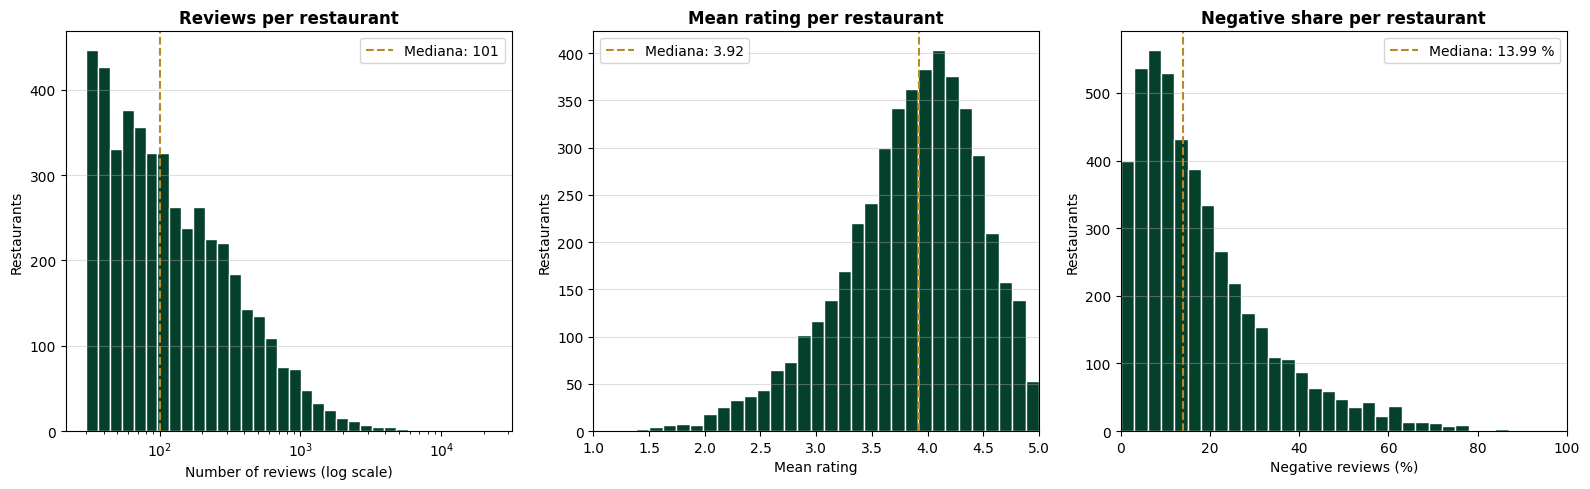

In [47]:
# 4.7.5. Chart restaurant-level reputation indicators
review_bins = np.logspace(
    np.log10(complete_diagnosis['reviews'].min()),
    np.log10(complete_diagnosis['reviews'].max()),
    35
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

axes[0].hist(
    complete_diagnosis['reviews'],
    bins=review_bins,
    color='#05402B',
    edgecolor='white'
)

axes[0].axvline(
    complete_diagnosis['reviews'].median(),
    color='#B58B2A',
    linestyle='--',
    label=(
        'Mediana: '
        f"{complete_diagnosis['reviews'].median():.0f}"
    )
)

axes[0].set_xscale('log')
axes[0].set_title(
    'Reviews per restaurant',
    fontweight='bold'
)
axes[0].set_xlabel(
    'Number of reviews (log scale)'
)
axes[0].set_ylabel('Restaurants')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.4)

axes[1].hist(
    complete_diagnosis['mean_review_rating'],
    bins=30,
    color='#05402B',
    edgecolor='white'
)

axes[1].axvline(
    complete_diagnosis[
        'mean_review_rating'
    ].median(),
    color='#B58B2A',
    linestyle='--',
    label=(
        'Mediana: '
        f"{complete_diagnosis['mean_review_rating'].median():.2f}"
    )
)

axes[1].set_title(
    'Mean rating per restaurant',
    fontweight='bold'
)
axes[1].set_xlabel('Mean rating')
axes[1].set_ylabel('Restaurants')
axes[1].set_xlim(1, 5)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.4)

axes[2].hist(
    complete_diagnosis['negative_percentage'],
    bins=30,
    color='#05402B',
    edgecolor='white'
)

axes[2].axvline(
    complete_diagnosis[
        'negative_percentage'
    ].median(),
    color='#B58B2A',
    linestyle='--',
    label=(
        'Mediana: '
        f"{complete_diagnosis['negative_percentage'].median():.2f} %"
    )
)

axes[2].set_title(
    'Negative share per restaurant',
    fontweight='bold'
)
axes[2].set_xlabel('Negative reviews (%)')
axes[2].set_ylabel('Restaurants')
axes[2].set_xlim(0, 100)
axes[2].legend()
axes[2].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

Among 4,670 restaurants with a full diagnosis, the median has 101 reviews and the mean is 236.38.

Median rating is 3.92; median Negative share is 13.99%, Positive share 73.33%, rating standard deviation 1.21, and historical coverage 2,826 days.

Weighted by review count, mean rating is 4.01 and Negative share is 13.47%. Unweighted, they are 3.84 and 18.04%. Restaurants with more reviews have better indicators in these data, without proving causation.

The final diagnosis compares restaurants within competitive groups, not against global percentiles.


### 4.7.6. Build time windows for reputation alerts

Compare two consecutive windows of six complete months in the historical dataset:

- **Previous:** June–November 2022.
- **Recent:** December 2022–May 2023.

Exclude June 2023 because the dataset stops on June 10, so the month is incomplete.

“Recent” means recent within the dataset, not recent today. The latest complete month is May 2023.

For each restaurant, count reviews and calculate mean rating and Negative share in each window. These measures support the later alert rules.


In [48]:
# 4.7.6. Build time windows for reputation alerts
temporal_data = data[
    [
        'review_id',
        'item_id',
        'date',
        'review_rating',
        'sentiment'
    ]
].copy()

temporal_data['is_negative'] = (
    temporal_data['sentiment']
    .eq('Negative')
    .astype('int8')
)

last_observed_month = (
    temporal_data['date']
    .max()
    .to_period('M')
)

last_complete_month = last_observed_month - 1

recent_start = (
    last_complete_month - 5
).to_timestamp()

recent_end = (
    last_complete_month + 1
).to_timestamp()

previous_start = (
    last_complete_month - 11
).to_timestamp()

previous_end = recent_start

print(
    'Previous window:',
    previous_start.strftime('%Y-%m-%d'),
    'to',
    (previous_end - pd.Timedelta(days=1)).strftime('%Y-%m-%d')
)

print(
    'Recent window:',
    recent_start.strftime('%Y-%m-%d'),
    'to',
    (recent_end - pd.Timedelta(days=1)).strftime('%Y-%m-%d')
)

Previous window: 2022-06-01 to 2022-11-30
Recent window: 2022-12-01 to 2023-05-31


In [49]:
# 4.7.6. Build time windows for reputation alerts
previous_window_reviews = temporal_data.loc[
    temporal_data['date'].ge(previous_start)
    & temporal_data['date'].lt(previous_end)
].copy()

recent_window_reviews = temporal_data.loc[
    temporal_data['date'].ge(recent_start)
    & temporal_data['date'].lt(recent_end)
].copy()

In [50]:
# 4.7.6. Build time windows for reputation alerts
previous_window_summary = (
    previous_window_reviews
    .groupby('item_id')
    .agg(
        previous_reviews=('review_id', 'size'),
        previous_negative_reviews=('is_negative', 'sum'),
        previous_mean_rating=('review_rating', 'mean'),
        previous_negative_percentage=(
            'is_negative',
            lambda series: series.mean() * 100
        )
    )
    .reset_index()
)

recent_window_summary = (
    recent_window_reviews
    .groupby('item_id')
    .agg(
        recent_reviews=('review_id', 'size'),
        recent_negative_reviews=('is_negative', 'sum'),
        recent_mean_rating=('review_rating', 'mean'),
        recent_negative_percentage=(
            'is_negative',
            lambda series: series.mean() * 100
        )
    )
    .reset_index()
)

In [51]:
# 4.7.6. Build time windows for reputation alerts
restaurant_temporal_diagnosis = (
    restaurant_reputation
    .merge(
        previous_window_summary,
        on='item_id',
        how='left',
        validate='one_to_one'
    )
    .merge(
        recent_window_summary,
        on='item_id',
        how='left',
        validate='one_to_one'
    )
)

window_count_columns = [
    'previous_reviews',
    'previous_negative_reviews',
    'recent_reviews',
    'recent_negative_reviews'
]

restaurant_temporal_diagnosis[window_count_columns] = (
    restaurant_temporal_diagnosis[window_count_columns]
    .fillna(0)
    .astype('int64')
)

restaurant_temporal_diagnosis[
    'has_activity_both_windows'
] = (
    restaurant_temporal_diagnosis['previous_reviews'].gt(0)
    & restaurant_temporal_diagnosis['recent_reviews'].gt(0)
)

restaurant_temporal_diagnosis['rating_change'] = (
    restaurant_temporal_diagnosis['recent_mean_rating']
    - restaurant_temporal_diagnosis['previous_mean_rating']
)

restaurant_temporal_diagnosis[
    'negative_percentage_point_change'
] = (
    restaurant_temporal_diagnosis['recent_negative_percentage']
    - restaurant_temporal_diagnosis['previous_negative_percentage']
)

In [52]:
# 4.7.6. Build time windows for reputation alerts
temporal_window_validation = pd.Series(
    {
        'previous_reviews': len(previous_window_reviews),
        'recent_reviews': len(recent_window_reviews),
        'previous_restaurants': (
            previous_window_reviews['item_id'].nunique()
        ),
        'recent_restaurants': (
            recent_window_reviews['item_id'].nunique()
        ),
        'restaurants_in_both_windows': (
            restaurant_temporal_diagnosis[
                'has_activity_both_windows'
            ].sum()
        ),
        'previous_negative_reviews': (
            previous_window_reviews['is_negative'].sum()
        ),
        'recent_negative_reviews': (
            recent_window_reviews['is_negative'].sum()
        )
    },
    name='result'
)

display(temporal_window_validation.to_frame())

,result
previous_reviews,35360
recent_reviews,38204
previous_restaurants,5068
recent_restaurants,5113
restaurants_in_both_windows,3762
previous_negative_reviews,5780
recent_negative_reviews,6147


In [53]:
# 4.7.6. Build time windows for reputation alerts
temporal_activity_distribution = (
    restaurant_temporal_diagnosis[
        [
            'previous_reviews',
            'recent_reviews'
        ]
    ]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .T
    .round(2)
)

display(temporal_activity_distribution)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
previous_reviews,10056.0,3.52,18.18,0.0,0.0,1.0,2.0,6.0,12.0,45.00,622.0
recent_reviews,10056.0,3.80,20.14,0.0,0.0,1.0,2.0,7.0,12.0,44.45,587.0


### Findings from the time windows

The recent window has 38,204 reviews and the previous one 35,360. Negative counts rise from 5,780 to 6,147, while their share falls from 16.35% to 16.09%.

There are 3,762 restaurants active in both windows. Many have few reviews, so alerts require a minimum count.

Market-wide trends cannot replace an individual restaurant diagnosis.


### 4.7.7. Test minimum time-window support

Compare thresholds of 3, 5, 10, and 20 reviews per restaurant in each window. Include only restaurants with at least 30 reviews in total and activity in both windows. Choose a minimum using both restaurant coverage and retained reviews.


In [54]:
# 4.7.7. Test minimum time-window support
temporal_candidates = (
    restaurant_temporal_diagnosis.loc[
        restaurant_temporal_diagnosis['reviews'].ge(30)
        & restaurant_temporal_diagnosis[
            'has_activity_both_windows'
        ]
    ]
    .copy()
)

candidate_restaurants = len(temporal_candidates)
candidate_previous_reviews = (
    temporal_candidates['previous_reviews'].sum()
)
candidate_recent_reviews = (
    temporal_candidates['recent_reviews'].sum()
)

temporal_candidate_summary = pd.Series(
    {
        'candidate_restaurants': candidate_restaurants,
        'previous_reviews': candidate_previous_reviews,
        'recent_reviews': candidate_recent_reviews,
        'previous_negative_reviews': (
            temporal_candidates[
                'previous_negative_reviews'
            ].sum()
        ),
        'recent_negative_reviews': (
            temporal_candidates[
                'recent_negative_reviews'
            ].sum()
        )
    },
    name='result'
)

display(temporal_candidate_summary.to_frame())

,result
candidate_restaurants,2814
previous_reviews,30663
recent_reviews,32014
previous_negative_reviews,4623
recent_negative_reviews,4873


In [55]:
# 4.7.7. Test minimum time-window support
minimum_reviews_options = [3, 5, 10, 20]
temporal_sensitivity_results = []

for minimum_reviews in minimum_reviews_options:

    eligible_restaurants = temporal_candidates.loc[
        temporal_candidates[
            'previous_reviews'
        ].ge(minimum_reviews)
        & temporal_candidates[
            'recent_reviews'
        ].ge(minimum_reviews)
    ]

    eligible_count = len(eligible_restaurants)

    eligible_previous_reviews = (
        eligible_restaurants['previous_reviews'].sum()
    )

    eligible_recent_reviews = (
        eligible_restaurants['recent_reviews'].sum()
    )

    temporal_sensitivity_results.append(
        {
            'minimum_reviews_per_window': minimum_reviews,
            'eligible_restaurants': eligible_count,
            'restaurant_coverage_percentage': (
                eligible_count
                / candidate_restaurants
                * 100
            ),
            'previous_reviews': eligible_previous_reviews,
            'previous_review_coverage_percentage': (
                eligible_previous_reviews
                / candidate_previous_reviews
                * 100
            ),
            'recent_reviews': eligible_recent_reviews,
            'recent_review_coverage_percentage': (
                eligible_recent_reviews
                / candidate_recent_reviews
                * 100
            )
        }
    )

temporal_sensitivity = (
    pd.DataFrame(temporal_sensitivity_results)
    .set_index('minimum_reviews_per_window')
    .round(2)
)

display(temporal_sensitivity)

,eligible_restaurants,restaurant_coverage_percentage,previous_reviews,previous_review_coverage_percentage,recent_reviews,recent_review_coverage_percentage
minimum_reviews_per_window,,,,,,
3,1567,55.69,27918,91.05,29038,90.70
5,1017,36.14,25351,82.68,26140,81.65
10,450,15.99,20480,66.79,21309,66.56
20,178,6.33,15914,51.90,16528,51.63


### Findings from the support test

Three reviews per window give 55.69% coverage, but one review changes a percentage by 33.33 points. Choose five: 1,017 restaurants remain, with about 82% of reviews in each window. Ten leaves 450 restaurants and twenty leaves 178. Five to nine reviews give moderate support; ten or more give stronger support. Alerts describe observed deterioration, not a forecast.


### 4.7.8. Select restaurants for alerts

Require at least five reviews in each window. Set support using the smaller count:

- **Moderate:** 5–9 reviews.
- **High:** 10–19 reviews.
- **Very high:** at least 20 reviews.

This separates early signals from those based on more reviews.


In [56]:
# 4.7.8. Select restaurants for alerts
minimum_temporal_reviews = 5

temporal_alert_base = (
    temporal_candidates.loc[
        temporal_candidates[
            'previous_reviews'
        ].ge(minimum_temporal_reviews)
        & temporal_candidates[
            'recent_reviews'
        ].ge(minimum_temporal_reviews)
    ]
    .copy()
)

temporal_alert_base[
    'minimum_window_reviews'
] = (
    temporal_alert_base[
        [
            'previous_reviews',
            'recent_reviews'
        ]
    ]
    .min(axis=1)
)

temporal_alert_base['temporal_support_level'] = pd.cut(
    temporal_alert_base['minimum_window_reviews'],
    bins=[4, 9, 19, np.inf],
    labels=[
        'Moderate (5-9)',
        'High (10-19)',
        'Very high (20 or more)'
    ],
    ordered=True
)

In [57]:
# 4.7.8. Select restaurants for alerts
temporal_alert_validation = pd.Series(
    {
        'eligible_restaurants': len(temporal_alert_base),
        'unique_restaurants': (
            temporal_alert_base['item_id'].nunique()
        ),
        'previous_reviews': (
            temporal_alert_base['previous_reviews'].sum()
        ),
        'recent_reviews': (
            temporal_alert_base['recent_reviews'].sum()
        ),
        'missing_rating_change': (
            temporal_alert_base['rating_change'].isna().sum()
        ),
        'missing_negative_change': (
            temporal_alert_base[
                'negative_percentage_point_change'
            ].isna().sum()
        )
    },
    name='result'
)

display(temporal_alert_validation.to_frame())

,result
eligible_restaurants,1017
unique_restaurants,1017
previous_reviews,25351
recent_reviews,26140
missing_rating_change,0
missing_negative_change,0


In [58]:
# 4.7.8. Select restaurants for alerts
temporal_support_summary = (
    temporal_alert_base
    .groupby(
        'temporal_support_level',
        observed=True
    )
    .agg(
        restaurants=('item_id', 'nunique'),
        previous_reviews=('previous_reviews', 'sum'),
        recent_reviews=('recent_reviews', 'sum')
    )
)

temporal_support_summary[
    'restaurant_percentage'
] = (
    temporal_support_summary['restaurants']
    .div(temporal_support_summary['restaurants'].sum())
    .mul(100)
)

temporal_support_summary = temporal_support_summary[
    [
        'restaurants',
        'restaurant_percentage',
        'previous_reviews',
        'recent_reviews'
    ]
].round(2)

display(temporal_support_summary)

,restaurants,restaurant_percentage,previous_reviews,recent_reviews
temporal_support_level,,,,
Moderate (5-9),567,55.75,4871,4831
High (10-19),272,26.75,4566,4781
Very high (20 or more),178,17.50,15914,16528


In [59]:
# 4.7.8. Select restaurants for alerts
temporal_change_distribution = (
    temporal_alert_base[
        [
            'rating_change',
            'negative_percentage_point_change'
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .T
    .round(2)
)

display(temporal_change_distribution)

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
rating_change,1017.0,-0.024795,0.675912,-2.333333,-1.662857,-1.093074,-0.836364,-0.397727,-0.038278,0.309091,0.817027,1.183654,1.893801,3.388889
negative_percentage_point_change,1017.0,0.28022,19.145192,-88.888889,-54.199134,-33.333333,-22.222222,-8.571429,0.0,10.0,22.945055,30.977273,50.0,83.333333


### Findings from the selected time sample

The sample has 1,017 restaurants and 51,491 reviews. Moderate support applies to 55.75%; the other 44.25% have at least ten reviews per window. Median rating change is −0.04 and median change in Negative share is zero. In the worst quartile, ratings fall at least 0.40 and Negative share rises ten percentage points; the worst decile reaches 0.84 and 22.95 points. Both measures come from the same underlying scores.


### 4.7.9. Define reputation alerts

Require both conditions:

- **Watch:** rating change ≤ −0.40 and Negative share increase ≥ 10 percentage points.
- **High alert:** rating change ≤ −0.80 and Negative share increase ≥ 20 points.
- **Critical alert:** rating change ≤ −1.00 and Negative share increase ≥ 30 points.

These are operational rules for historical changes up to May 2023. They do not predict future reputation or provide current alerts.


In [60]:
# 4.7.9. Define reputation alerts
critical_alert_condition = (
    temporal_alert_base['rating_change'].le(-1.00)
    & temporal_alert_base[
        'negative_percentage_point_change'
    ].ge(30.00)
)

high_alert_condition = (
    temporal_alert_base['rating_change'].le(-0.80)
    & temporal_alert_base[
        'negative_percentage_point_change'
    ].ge(20.00)
)

watch_condition = (
    temporal_alert_base['rating_change'].le(-0.40)
    & temporal_alert_base[
        'negative_percentage_point_change'
    ].ge(10.00)
)

temporal_alert_base['alert_level'] = np.select(
    [
        critical_alert_condition,
        high_alert_condition,
        watch_condition
    ],
    [
        'Critical alert',
        'High alert',
        'Watch'
    ],
    default='No alert'
)

alert_order = [
    'No alert',
    'Watch',
    'High alert',
    'Critical alert'
]

temporal_alert_base['alert_level'] = pd.Categorical(
    temporal_alert_base['alert_level'],
    categories=alert_order,
    ordered=True
)

In [61]:
# 4.7.9. Define reputation alerts
alert_summary = (
    temporal_alert_base['alert_level']
    .value_counts(sort=False)
    .reindex(alert_order, fill_value=0)
    .rename_axis('alert_level')
    .to_frame('restaurants')
)

alert_summary['restaurant_percentage'] = (
    alert_summary['restaurants']
    .div(alert_summary['restaurants'].sum())
    .mul(100)
    .round(2)
)

display(alert_summary)

print(
    'Restaurants evaluated:',
    f'{len(temporal_alert_base):,}'
)

print(
    'Restaurants with a signal:',
    f"{alert_summary.loc[
        ['Watch', 'High alert', 'Critical alert'],
        'restaurants'
    ].sum():,}"
)

,restaurants,restaurant_percentage
alert_level,,
No alert,818,80.43
Watch,114,11.21
High alert,40,3.93
Critical alert,45,4.42


Restaurants evaluated: 1,017
Restaurants with a signal: 199


In [62]:
# 4.7.9. Define reputation alerts
alert_support_table = pd.crosstab(
    temporal_alert_base['alert_level'],
    temporal_alert_base['temporal_support_level'],
    margins=True,
    margins_name='Total'
)

display(alert_support_table)

temporal_support_level,Moderate (5-9),High (10-19),Very high (20 or more),Total
alert_level,,,,
No alert,434,218,166,818
Watch,75,34,5,114
High alert,23,13,4,40
Critical alert,35,7,3,45
Total,567,272,178,1017


In [63]:
# 4.7.9. Define reputation alerts
restaurant_alerts = (
    temporal_alert_base.loc[
        temporal_alert_base['alert_level'].ne('No alert'),
        [
            'item_id',
            'name',
            'price_interval',
            'previous_reviews',
            'recent_reviews',
            'minimum_window_reviews',
            'previous_mean_rating',
            'recent_mean_rating',
            'rating_change',
            'previous_negative_percentage',
            'recent_negative_percentage',
            'negative_percentage_point_change',
            'temporal_support_level',
            'alert_level'
        ]
    ]
    .sort_values(
        by=[
            'alert_level',
            'minimum_window_reviews',
            'rating_change'
        ],
        ascending=[
            False,
            False,
            True
        ]
    )
)

display(restaurant_alerts.head(20).round(2))

,item_id,name,price_interval,previous_reviews,recent_reviews,minimum_window_reviews,previous_mean_rating,recent_mean_rating,rating_change,previous_negative_percentage,recent_negative_percentage,negative_percentage_point_change,temporal_support_level,alert_level
1543,12858177,Ramses Madrid,Premium,56,22,22,4.41,3.32,-1.09,10.71,40.91,30.19,Very high (20 or more),Critical alert
8913,796535,La Cabana Argentina,Mid-range,33,21,21,4.64,3.62,-1.02,0.00,33.33,33.33,Very high (20 or more),Critical alert
9308,8624158,Txapela,Mid-range,60,20,20,4.35,2.8,-1.55,15.00,55.00,40.00,Very high (20 or more),Critical alert
8917,797208,Viridiana,Premium,39,17,17,4.82,3.41,-1.41,5.13,35.29,30.17,High (10-19),Critical alert
3665,1829992,El Tigre,Budget,16,16,16,3.88,2.75,-1.12,18.75,50.00,31.25,High (10-19),Critical alert
336,10472330,Casa Carmen Arturo Soria,Mid-range,12,20,12,3.42,1.8,-1.62,41.67,85.00,43.33,High (10-19),Critical alert
8299,6922754,Hattori Hanzo,Mid-range,12,13,12,3.83,2.77,-1.06,16.67,61.54,44.87,High (10-19),Critical alert
1626,12912040,Santerra Restaurante,Premium,11,14,11,4.64,3.43,-1.21,0.00,35.71,35.71,High (10-19),Critical alert
7495,5493060,El Gran Barril,Premium,10,13,10,4.0,2.54,-1.46,10.00,61.54,51.54,High (10-19),Critical alert
9536,921496,La Sirena Verde,Mid-range,17,10,10,3.53,2.2,-1.33,29.41,70.00,40.59,High (10-19),Critical alert


### Findings from the reputation alerts

Among 1,017 restaurants, 818 (80.43%) have no alert and 199 (19.57%) have a deterioration signal: 114 Watch, 40 High alert, and 45 Critical alert. Of the 199 signals, 133 have Moderate support; 35 of the 45 Critical alerts are in this group and need more reviews. The other 66 signals have at least ten reviews in each window. Keep severity and support separate.


### 4.7.10. Set action priorities

- **Immediate attention:** Critical alert and at least ten reviews in each window.
- **Priority review:** High alert and at least ten.
- **Monitor:** Watch and at least ten.
- **Check with more data:** any alert with five to nine.
- **No immediate action:** No alert.

Priority combines severity and evidence.


In [64]:
# 4.7.10. Set action priorities
higher_support_condition = (
    temporal_alert_base['minimum_window_reviews'].ge(10)
)

temporal_alert_base['operational_priority'] = np.select(
    [
        temporal_alert_base['alert_level'].eq(
            'Critical alert'
        )
        & higher_support_condition,

        temporal_alert_base['alert_level'].eq(
            'High alert'
        )
        & higher_support_condition,

        temporal_alert_base['alert_level'].eq(
            'Watch'
        )
        & higher_support_condition,

        temporal_alert_base['alert_level'].ne(
            'No alert'
        )
        & ~higher_support_condition
    ],
    [
        'Immediate attention',
        'Priority review',
        'Monitor',
        'Check with more data'
    ],
    default='No immediate action'
)

priority_order = [
    'No immediate action',
    'Check with more data',
    'Monitor',
    'Priority review',
    'Immediate attention'
]

temporal_alert_base['operational_priority'] = (
    pd.Categorical(
        temporal_alert_base['operational_priority'],
        categories=priority_order,
        ordered=True
    )
)

In [65]:
# 4.7.10. Set action priorities
operational_priority_summary = (
    temporal_alert_base['operational_priority']
    .value_counts(sort=False)
    .reindex(priority_order, fill_value=0)
    .rename_axis('operational_priority')
    .to_frame('restaurants')
)

operational_priority_summary[
    'restaurant_percentage'
] = (
    operational_priority_summary['restaurants']
    .div(operational_priority_summary['restaurants'].sum())
    .mul(100)
    .round(2)
)

display(operational_priority_summary)

,restaurants,restaurant_percentage
operational_priority,,
No immediate action,818,80.43
Check with more data,133,13.08
Monitor,39,3.83
Priority review,17,1.67
Immediate attention,10,0.98


In [66]:
# 4.7.10. Set action priorities
operational_alerts = (
    temporal_alert_base.loc[
        temporal_alert_base[
            'operational_priority'
        ].ne('No immediate action'),
        [
            'item_id',
            'name',
            'price_interval',
            'previous_reviews',
            'recent_reviews',
            'minimum_window_reviews',
            'previous_mean_rating',
            'recent_mean_rating',
            'rating_change',
            'previous_negative_percentage',
            'recent_negative_percentage',
            'negative_percentage_point_change',
            'temporal_support_level',
            'alert_level',
            'operational_priority'
        ]
    ]
    .sort_values(
        by=[
            'operational_priority',
            'minimum_window_reviews',
            'rating_change'
        ],
        ascending=[
            False,
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

display(operational_alerts.head(20).round(2))

,item_id,name,price_interval,previous_reviews,recent_reviews,minimum_window_reviews,previous_mean_rating,recent_mean_rating,rating_change,previous_negative_percentage,recent_negative_percentage,negative_percentage_point_change,temporal_support_level,alert_level,operational_priority
0,12858177,Ramses Madrid,Premium,56,22,22,4.41,3.32,-1.09,10.71,40.91,30.19,Very high (20 or more),Critical alert,Immediate attention
1,796535,La Cabana Argentina,Mid-range,33,21,21,4.64,3.62,-1.02,0.00,33.33,33.33,Very high (20 or more),Critical alert,Immediate attention
2,8624158,Txapela,Mid-range,60,20,20,4.35,2.8,-1.55,15.00,55.00,40.00,Very high (20 or more),Critical alert,Immediate attention
3,797208,Viridiana,Premium,39,17,17,4.82,3.41,-1.41,5.13,35.29,30.17,High (10-19),Critical alert,Immediate attention
4,1829992,El Tigre,Budget,16,16,16,3.88,2.75,-1.12,18.75,50.00,31.25,High (10-19),Critical alert,Immediate attention
5,10472330,Casa Carmen Arturo Soria,Mid-range,12,20,12,3.42,1.8,-1.62,41.67,85.00,43.33,High (10-19),Critical alert,Immediate attention
6,6922754,Hattori Hanzo,Mid-range,12,13,12,3.83,2.77,-1.06,16.67,61.54,44.87,High (10-19),Critical alert,Immediate attention
7,12912040,Santerra Restaurante,Premium,11,14,11,4.64,3.43,-1.21,0.00,35.71,35.71,High (10-19),Critical alert,Immediate attention
8,5493060,El Gran Barril,Premium,10,13,10,4.0,2.54,-1.46,10.00,61.54,51.54,High (10-19),Critical alert,Immediate attention
9,921496,La Sirena Verde,Mid-range,17,10,10,3.53,2.2,-1.33,29.41,70.00,40.59,High (10-19),Critical alert,Immediate attention


### Findings from action priorities

Time-based monitoring is available for 1,017 of 10,056 restaurants (10.11%): each needs at least five reviews in both windows. The remaining 9,039 (89.89%) are `Not evaluable`, which is not an alert. Among eligible restaurants, 818 (80.43%) need no immediate action and 199 (19.57%) have a signal. Ten require Immediate attention, 17 Priority review, 39 Monitor, and 133 Check with more data. Restaurants with unknown prices may receive alerts, but are excluded from price-based comparisons.


## 4.8. Main findings

- Analyze 1,157,800 reviews from 10,056 restaurants.
- Positive reviews are 74.71%; focus on macro F1, Negative recall, and balanced accuracy with class weights.
- Source language labels are 82.8% Spanish and 17.2% English; train one model and evaluate by language label.
- Two historical six-month windows ending in May 2023 make 1,017 restaurants eligible for signals of past deterioration; 199 show a signal and ten meet the highest action-priority rule. These are not current alerts.
- Known prices cover 98.04% of reviews and support benchmarking.
- The 30-restaurant, 1,000-review rule gives 55 groups across 32 cuisine types.
- A full diagnosis covers 4,670 restaurants and 95.35% of reviews.
- The classifier uses only `title` and `text`, avoiding direct rating leakage.


# 5. Prepare the modeling corpus

Build the corpus for notebook 3 with only the columns needed for training, splitting, and evaluation. Fit TF-IDF and any other text transformations **after** splitting, on training data only.


## 5.1. Build modeling text

Combine each review title and body in `review_text`. Keep capitalization, accents, punctuation, and the original language so different NLP methods can be compared.

Keep `review_id` for traceability, `item_id` for grouped splitting, `date` for time-based checks, `language` for evaluation by language label, `review_text` as the only input, and `sentiment` as the target. Do not use ratings, price, or restaurant-level aggregates as predictors.


In [67]:
# 5.1. Build modeling text
modeling_corpus = data[
    [
        'review_id',
        'item_id',
        'date',
        'language',
        'title',
        'text',
        'sentiment'
    ]
].copy()

modeling_corpus['title'] = (
    modeling_corpus['title']
    .astype('string')
    .fillna('')
    .str.strip()
)

modeling_corpus['text'] = (
    modeling_corpus['text']
    .astype('string')
    .fillna('')
    .str.strip()
)

modeling_corpus['review_text'] = np.where(
    modeling_corpus['title'].eq(''),
    modeling_corpus['text'],
    np.where(
        modeling_corpus['text'].eq(''),
        modeling_corpus['title'],
        modeling_corpus['title']
        + '. '
        + modeling_corpus['text']
    )
)

modeling_corpus['review_text'] = (
    modeling_corpus['review_text']
    .astype('string')
    .str.strip()
)

modeling_corpus = modeling_corpus[
    [
        'review_id',
        'item_id',
        'date',
        'language',
        'review_text',
        'sentiment'
    ]
].copy()

## 5.2. Validate the corpus


In [68]:
# 5.2. Validate the corpus
modeling_corpus_validation = pd.Series(
    {
        'rows': len(modeling_corpus),
        'unique_review_ids': (
            modeling_corpus['review_id'].nunique()
        ),
        'unique_restaurants': (
            modeling_corpus['item_id'].nunique()
        ),
        'duplicated_review_ids': (
            modeling_corpus['review_id'].duplicated().sum()
        ),
        'missing_review_text': (
            modeling_corpus['review_text'].isna().sum()
        ),
        'empty_review_text': (
            modeling_corpus['review_text'].eq('').sum()
        ),
        'missing_sentiment': (
            modeling_corpus['sentiment'].isna().sum()
        ),
        'missing_language': (
            modeling_corpus['language'].isna().sum()
        ),
        'missing_dates': (
            modeling_corpus['date'].isna().sum()
        )
    },
    name='result'
)

display(modeling_corpus_validation.to_frame())

,result
rows,1157800
unique_review_ids,1157800
unique_restaurants,10056
duplicated_review_ids,0
missing_review_text,0
empty_review_text,0
missing_sentiment,0
missing_language,0
missing_dates,0


### Corpus validation findings

The corpus has 1,157,800 reviews from 10,056 restaurants. Review IDs are unique, and there are no empty texts or missing values. Split the data before fitting any text-processing step.


## 5.3. Stratified, restaurant-grouped split

Aim for about 80% training, 10% validation, and 10% test reviews. Stratify by sentiment and group by `item_id`: all reviews of a restaurant stay in one partition. Keep the test set separate until model selection is complete. Fit TF-IDF and other text transformations on training data only.


In [69]:


# 5.3. Stratified, restaurant-grouped split
split_target = modeling_corpus['sentiment'].to_numpy()
split_groups = modeling_corpus['item_id'].to_numpy()
dummy_features = np.zeros(
    len(modeling_corpus),
    dtype='int8'
)

test_splitter = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

development_indices, test_indices = next(
    test_splitter.split(
        dummy_features,
        split_target,
        groups=split_groups
    )
)

validation_splitter = StratifiedGroupKFold(
    n_splits=9,
    shuffle=True,
    random_state=43
)

train_relative_indices, validation_relative_indices = next(
    validation_splitter.split(
        dummy_features[development_indices],
        split_target[development_indices],
        groups=split_groups[development_indices]
    )
)

train_indices = development_indices[
    train_relative_indices
]

validation_indices = development_indices[
    validation_relative_indices
]

split_labels = np.full(
    len(modeling_corpus),
    '',
    dtype=object
)

split_labels[train_indices] = 'train'
split_labels[validation_indices] = 'validation'
split_labels[test_indices] = 'test'

split_order = [
    'train',
    'validation',
    'test'
]

modeling_corpus['dataset_split'] = pd.Categorical(
    split_labels,
    categories=split_order,
    ordered=True
)

In [70]:
# 5.3. Stratified, restaurant-grouped split
split_summary = (
    modeling_corpus
    .groupby('dataset_split', observed=True)
    .agg(
        reviews=('review_id', 'size'),
        restaurants=('item_id', 'nunique')
    )
    .reindex(split_order)
)

split_summary['review_percentage'] = (
    split_summary['reviews']
    .div(split_summary['reviews'].sum())
    .mul(100)
)

split_summary['restaurant_percentage'] = (
    split_summary['restaurants']
    .div(split_summary['restaurants'].sum())
    .mul(100)
)

split_summary = split_summary[
    [
        'reviews',
        'review_percentage',
        'restaurants',
        'restaurant_percentage'
    ]
].round(2)

display(split_summary)

,reviews,review_percentage,restaurants,restaurant_percentage
dataset_split,,,,
train,931880,80.49,8025,79.80
validation,115008,9.93,1035,10.29
test,110912,9.58,996,9.90


In [71]:
# 5.3. Stratified, restaurant-grouped split
train_restaurants = set(
    modeling_corpus.loc[
        modeling_corpus['dataset_split'].eq('train'),
        'item_id'
    ]
)

validation_restaurants = set(
    modeling_corpus.loc[
        modeling_corpus['dataset_split'].eq('validation'),
        'item_id'
    ]
)

test_restaurants = set(
    modeling_corpus.loc[
        modeling_corpus['dataset_split'].eq('test'),
        'item_id'
    ]
)

split_validation = pd.Series(
    {
        'unassigned_reviews': (
            modeling_corpus['dataset_split'].isna().sum()
        ),
        'train_validation_overlap': len(
            train_restaurants & validation_restaurants
        ),
        'train_test_overlap': len(
            train_restaurants & test_restaurants
        ),
        'validation_test_overlap': len(
            validation_restaurants & test_restaurants
        )
    },
    name='result'
)

display(split_validation.to_frame())

,result
unassigned_reviews,0
train_validation_overlap,0
train_test_overlap,0
validation_test_overlap,0


In [72]:
# 5.3. Stratified, restaurant-grouped split
split_sentiment_percentage = (
    pd.crosstab(
        modeling_corpus['dataset_split'],
        modeling_corpus['sentiment'],
        normalize='index'
    )
    .mul(100)
    .reindex(
        index=split_order,
        columns=sentiment_order
    )
    .round(2)
)

display(split_sentiment_percentage)

sentiment,Negative,Neutral,Positive
dataset_split,,,
train,13.92,11.57,74.51
validation,13.33,10.98,75.69
test,13.65,10.96,75.39


### Split findings

The split has 931,880 training reviews, 115,008 validation reviews, and 110,912 test reviews: 80.49%, 9.93%, and 9.58%. It contains 8,025, 1,035, and 996 restaurants with no overlap. Class shares remain similar. Grouping explains the differences from an exact 80/10/10 split; fixed seeds support reproducibility.


## 5.4. Save the modeling corpus

Save the corpus and its split in compressed Parquet. This format preserves data types and supports efficient reading.


In [73]:


# 5.4. Save the modeling corpus
modeling_corpus_path = (
    DATA_PATH / 'modeling_corpus.parquet'
)

modeling_corpus.to_parquet(
    modeling_corpus_path,
    index=False,
    engine='pyarrow',
    compression='snappy'
)

In [74]:
# 5.4. Save the modeling corpus
parquet_file = pq.ParquetFile(
    modeling_corpus_path
)

export_validation = pd.Series(
    {
        'file': modeling_corpus_path.name,
        'exists': modeling_corpus_path.exists(),
        'rows': parquet_file.metadata.num_rows,
        'columns': len(parquet_file.schema_arrow.names),
        'row_groups': parquet_file.metadata.num_row_groups,
        'size_mb': (
            modeling_corpus_path.stat().st_size
            / 1024 ** 2
        )
    },
    name='result'
).to_frame()

display(export_validation.round(2))

,result
file,modeling_corpus.parquet
exists,True
rows,1157800
columns,7
row_groups,2
size_mb,272.712769


### Saved corpus

The Parquet file contains 1,157,800 reviews, seven columns, and the reproducible split. Its earlier run used 272.71 MB; check the current file metadata below for its actual size.


## 5.5. Save analytical products

Save restaurant-level diagnosis, time-window alerts, eligible competitive group membership, and group support in separate files. The app can read these prepared results without recomputing the full analysis.


In [75]:
# 5.5. Save analytical products
benchmark_membership_export = (
    benchmark_membership[
        [
            'item_id',
            'specialty',
            'price_interval'
        ]
    ]
    .drop_duplicates()
    .merge(
        restaurant_reputation[
            [
                'item_id',
                'reviews'
            ]
        ],
        on='item_id',
        how='left',
        validate='many_to_one'
    )
)

benchmark_group_support_export = (
    benchmark_membership_export
    .groupby(
        [
            'specialty',
            'price_interval'
        ],
        observed=True
    )
    .agg(
        restaurants=('item_id', 'nunique'),
        reviews=('reviews', 'sum')
    )
    .reset_index()
)

eligible_benchmark_groups_export = (
    benchmark_group_support_export.loc[
        benchmark_group_support_export[
            'restaurants'
        ].ge(30)
        & benchmark_group_support_export[
            'reviews'
        ].ge(1_000)
    ]
    .copy()
)

eligible_benchmark_membership_export = (
    benchmark_membership_export
    .merge(
        eligible_benchmark_groups_export[
            [
                'specialty',
                'price_interval'
            ]
        ],
        on=[
            'specialty',
            'price_interval'
        ],
        how='inner',
        validate='many_to_one'
    )
)

In [76]:
benchmark_export_validation = pd.Series(
    {
        'eligible_groups': (
            len(eligible_benchmark_groups_export)
        ),
        'eligible_specialties': (
            eligible_benchmark_groups_export[
                'specialty'
            ].nunique()
        ),
        'membership_rows': (
            len(eligible_benchmark_membership_export)
        ),
        'unique_restaurants': (
            eligible_benchmark_membership_export[
                'item_id'
            ].nunique()
        ),
        'duplicated_memberships': (
            eligible_benchmark_membership_export[
                [
                    'item_id',
                    'specialty',
                    'price_interval'
                ]
            ]
            .duplicated()
            .sum()
        )
    },
    name='result'
)

display(benchmark_export_validation.to_frame())

,result
eligible_groups,55
eligible_specialties,32
membership_rows,11541
unique_restaurants,6996
duplicated_memberships,0


In [77]:
# 5.5. Save analytical products
alert_classification = temporal_alert_base[
    [
        'item_id',
        'minimum_window_reviews',
        'temporal_support_level',
        'alert_level',
        'operational_priority'
    ]
].copy()

status_columns = [
    'temporal_support_level',
    'alert_level',
    'operational_priority'
]

for column in status_columns:
    alert_classification[column] = (
        alert_classification[column]
        .astype('string')
    )

restaurant_diagnostics_export = (
    restaurant_temporal_diagnosis
    .merge(
        alert_classification,
        on='item_id',
        how='left',
        validate='one_to_one'
    )
)

restaurant_diagnostics_export['alert_evaluable'] = (
    restaurant_diagnostics_export[
        'alert_level'
    ].notna()
)

restaurant_diagnostics_export[
    status_columns
] = (
    restaurant_diagnostics_export[
        status_columns
    ]
    .fillna('Not evaluable')
)

restaurant_diagnostics_export[
    'minimum_window_reviews'
] = (
    restaurant_diagnostics_export[
        'minimum_window_reviews'
    ]
    .astype('Int64')
)

In [78]:
# 5.5. Save analytical products
product_validation = pd.Series(
    {
        'diagnostic_restaurants': (
            len(restaurant_diagnostics_export)
        ),
        'unique_diagnostic_restaurants': (
            restaurant_diagnostics_export[
                'item_id'
            ].nunique()
        ),
        'evaluable_alerts': (
            restaurant_diagnostics_export[
                'alert_evaluable'
            ].sum()
        ),
        'non_evaluable_alerts': (
            restaurant_diagnostics_export[
                'alert_level'
            ].eq('Not evaluable').sum()
        ),
        'restaurants_with_signal': (
            restaurant_diagnostics_export[
                'alert_level'
            ].isin(
                [
                    'Watch',
                    'High alert',
                    'Critical alert'
                ]
            ).sum()
        ),
        'eligible_benchmark_groups': (
            len(eligible_benchmark_groups_export)
        ),
        'benchmark_membership_rows': (
            len(eligible_benchmark_membership_export)
        ),
        'benchmark_restaurants': (
            eligible_benchmark_membership_export[
                'item_id'
            ].nunique()
        )
    },
    name='result'
)

display(product_validation.to_frame())

,result
diagnostic_restaurants,10056
unique_diagnostic_restaurants,10056
evaluable_alerts,1017
non_evaluable_alerts,9039
restaurants_with_signal,199
eligible_benchmark_groups,55
benchmark_membership_rows,11541
benchmark_restaurants,6996


In [79]:
# 5.5. Save analytical products
product_outputs = {
    'restaurant_diagnostics': {
        'data': restaurant_diagnostics_export,
        'path': DATA_PATH / 'restaurant_diagnostics.parquet'
    },
    'benchmark_membership': {
        'data': eligible_benchmark_membership_export,
        'path': DATA_PATH / 'benchmark_membership.parquet'
    },
    'benchmark_groups': {
        'data': eligible_benchmark_groups_export,
        'path': DATA_PATH / 'benchmark_groups.parquet'
    }
}

for product in product_outputs.values():
    product['data'].to_parquet(
        product['path'],
        index=False,
        engine='pyarrow',
        compression='snappy'
    )

In [80]:
# 5.5. Save analytical products
exported_products_validation = []

for product_name, product in product_outputs.items():

    parquet_file = pq.ParquetFile(
        product['path']
    )

    exported_products_validation.append(
        {
            'product': product_name,
            'file': product['path'].name,
            'exists': product['path'].exists(),
            'rows': parquet_file.metadata.num_rows,
            'columns': len(
                parquet_file.schema_arrow.names
            ),
            'size_mb': (
                product['path'].stat().st_size
                / 1024 ** 2
            )
        }
    )

exported_products_validation = (
    pd.DataFrame(exported_products_validation)
    .set_index('product')
    .round(2)
)

display(exported_products_validation)

,file,exists,rows,columns,size_mb
product,,,,,
restaurant_diagnostics,restaurant_diagnostics.parquet,True,10056,35,0.69
benchmark_membership,benchmark_membership.parquet,True,11541,4,0.10
benchmark_groups,benchmark_groups.parquet,True,55,4,0.00


## 5.6. Save methodology settings

Save key decisions in a configuration file so notebook 3 and the app use the same rules.


In [81]:


# 5.6. Save methodology settings
project_config = {
    'project': (
        'Restaurant reputation diagnosis and competitive '
        'benchmarking in Madrid'
    ),
    'files': {
        'modeling_corpus': 'modeling_corpus.parquet',
        'restaurant_diagnostics': (
            'restaurant_diagnostics.parquet'
        ),
        'benchmark_membership': (
            'benchmark_membership.parquet'
        ),
        'benchmark_groups': 'benchmark_groups.parquet'
    },
    'sentiment': {
        'target': 'sentiment',
        'predictor': 'review_text',
        'classes': [
            'Negative',
            'Neutral',
            'Positive'
        ],
        'rating_mapping': {
            'Negative': [1, 2],
            'Neutral': [3],
            'Positive': [4, 5]
        }
    },
    'split': {
        'method': 'StratifiedGroupKFold',
        'group': 'item_id',
        'test_random_state': 42,
        'validation_random_state': 43,
        'approximate_proportions': {
            'train': 0.80,
            'validation': 0.10,
            'test': 0.10
        }
    },
    'benchmarking': {
        'minimum_restaurants': 30,
        'minimum_reviews': 1000
    },
    'historical_diagnosis': {
        'minimum_reviews_per_restaurant': 30
    },
    'temporal_alert': {
        'as_of_date': (recent_end - pd.Timedelta(days=1)).date().isoformat(),
        'last_observed_review_date': data['date'].max().date().isoformat(),
        'historical_snapshot': True,
        'window_months': 6,
        'minimum_reviews_per_window': 5,
        'higher_support_reviews': 10,
        'watch': {
            'maximum_rating_change': -0.40,
            'minimum_negative_change': 10.00
        },
        'high_alert': {
            'maximum_rating_change': -0.80,
            'minimum_negative_change': 20.00
        },
        'critical_alert': {
            'maximum_rating_change': -1.00,
            'minimum_negative_change': 30.00
        }
    },
    'excluded_predictors': [
        'review_rating',
        'restaurant_rating',
        'price_interval',
        'specialty',
        'language',
        'date',
        'item_id',
        'review_id'
    ]
}

project_config_path = (
    DATA_PATH / 'project_config.json'
)

with project_config_path.open(
    mode='w',
    encoding='utf-8'
) as config_file:
    json.dump(
        project_config,
        config_file,
        ensure_ascii=False,
        indent=4
    )

print(
    'Configuration saved to:',
    project_config_path
)

Configuration saved to: data/project_config.json


## 5.7. Notebook 2 findings

The analysis describes 1,157,800 reviews, 10,056 restaurants, class imbalance, and minimum evidence rules. It builds restaurant-level diagnosis, time alerts, and competitive groups. The bilingual text corpus uses review text as its only model input and groups the split by restaurant. Prepared products are saved for modeling and the app. The test set remains separate until final model selection.
